# Aprendizado não supervisionado aplicado a perfis de consumo elétrico

## Agrupamento de dias de operação com dados reais de energia

**Curso:** Inteligência Artificial para Engenharia Elétrica  
**Ambiente recomendado:** Google Colab ou Jupyter Notebook  
**Linguagem:** Python  
**Nível:** introdutório, com desenvolvimento gradual e explicações detalhadas

Este notebook apresenta um fluxo completo de aprendizado não supervisionado. O estudo começa com medições elétricas em intervalos de um minuto e termina com a identificação, a comparação e a interpretação de perfis diários de consumo. Cada transformação é explicada antes de sua execução, e cada resultado é acompanhado por orientações de leitura.

O propósito não é apenas executar algoritmos. Pretende-se compreender o que cada linha do fluxo representa fisicamente, quais hipóteses são assumidas, como os parâmetros afetam o resultado e por que um agrupamento matematicamente possível pode não ser útil para a Engenharia Elétrica.


## Como utilizar este material

A execução deve seguir a ordem das células. Uma célula de texto apresenta o conceito e informa o que será realizado. A célula de código seguinte implementa a etapa. Depois do resultado, uma nova explicação orienta sua interpretação.

Recomenda-se observar quatro perguntas durante toda a atividade:

1. O que representa cada linha da matriz entregue ao algoritmo?
2. O que representa cada coluna?
3. Como a semelhança entre duas linhas está sendo medida?
4. O agrupamento encontrado possui significado elétrico e operacional?

Se uma dessas perguntas não puder ser respondida, o resultado ainda não está suficientemente compreendido.


## Objetivos de aprendizagem

Ao final da execução, espera-se que seja possível:

1. distinguir aprendizado supervisionado e não supervisionado;
2. transformar uma série temporal elétrica em uma matriz adequada para agrupamento;
3. explicar por que escala, distância e escolha de atributos alteram os grupos;
4. aplicar e interpretar K-means, agrupamento hierárquico, DBSCAN e misturas gaussianas;
5. utilizar inércia, silhueta, Davies-Bouldin, Calinski-Harabasz, AIC e BIC;
6. empregar PCA para visualização e redução de dimensionalidade;
7. interpretar perfis de carga médios e relacioná-los à operação de uma rede inteligente;
8. reconhecer limitações, instabilidade, incerteza e ausência de uma resposta única.


## Visão geral do fluxo

O objeto original é uma série temporal: existe uma medição para cada minuto. Algoritmos de agrupamento, entretanto, recebem uma matriz em que cada linha é uma amostra e cada coluna é um atributo. Neste estudo, cada amostra será um dia de operação.

A transformação seguirá a sequência:

**medições por minuto → verificação da qualidade → atributos diários → padronização → agrupamento → avaliação → interpretação elétrica**

Um dia será descrito por energia total, demanda de pico, fator de carga, variabilidade, comportamento de tensão, participação de períodos do dia e participação dos circuitos submedidos. Assim, dois dias serão considerados semelhantes quando apresentarem combinações próximas dessas características.


## 1. Preparação do ambiente

As bibliotecas utilizadas possuem funções distintas:

| Biblioteca | Finalidade |
|---|---|
| NumPy | operações numéricas e vetoriais |
| pandas | leitura, limpeza, agregação e organização tabular |
| Matplotlib e seaborn | construção de gráficos |
| scikit-learn | pré-processamento, PCA, agrupamento e métricas |
| SciPy | cálculo do dendrograma hierárquico |

A semente aleatória é fixada para permitir que a execução seja reproduzida. Isso não elimina a aleatoriedade dos algoritmos, mas faz com que a mesma sequência pseudoaleatória seja utilizada em novas execuções.


In [ ]:
import os
import sys
import shutil
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

SEMENTE = 42
np.random.seed(SEMENTE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 120

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)


Python: 3.13.15
NumPy: 2.1.3
pandas: 2.2.3


### Interpretação da saída

As versões são registradas porque bibliotecas evoluem. Uma diferença de versão pode alterar valores padrão, mensagens ou detalhes numéricos. Os resultados gerais devem permanecer equivalentes, mas pequenas diferenças são esperadas.

O notebook foi escrito somente com bibliotecas normalmente disponíveis no Google Colab. Não é necessária uma instalação adicional na configuração padrão desse ambiente.


## 2. Fundamento: o que é aprendizado não supervisionado?

No aprendizado supervisionado, cada amostra possui uma resposta conhecida. Um modelo poderia receber medições de tensão e corrente e aprender, por exemplo, a prever uma classe previamente registrada como operação normal ou defeituosa.

No aprendizado não supervisionado, essa resposta não existe. O conjunto contém apenas as características observadas. O algoritmo procura estrutura interna, como grupos, regiões densas, direções de maior variação ou observações pouco usuais.

Neste estudo, não existe uma coluna chamada tipo_de_dia. O objetivo é construir essa informação de forma exploratória. Os grupos encontrados não são verdades físicas previamente certificadas. Eles são partições produzidas por uma definição de semelhança, pelos atributos escolhidos e pelas hipóteses do algoritmo.


### Vocabulário mínimo

| Termo | Significado neste notebook |
|---|---|
| Amostra | um dia de medições elétricas |
| Atributo ou feature | uma medida que descreve o dia, como energia ou demanda de pico |
| Espaço de atributos | sistema de coordenadas formado por todos os atributos |
| Distância | número que quantifica quão diferentes são duas amostras |
| Similaridade | ideia inversa da distância, valores próximos representam maior semelhança |
| Cluster ou grupo | conjunto de amostras consideradas semelhantes |
| Centroide | ponto médio usado para representar um grupo no K-means |
| Rótulo de grupo | número atribuído pelo algoritmo, sem ordem ou significado automático |
| Ruído | observação que o DBSCAN não conseguiu associar a uma região densa |

O rótulo 0 não significa melhor, menor ou normal. O rótulo 1 também não significa defeito. Esses números são identificadores arbitrários.


## 3. Contexto de Engenharia Elétrica

Redes elétricas inteligentes dependem de medição, comunicação e análise para compreender como a carga varia. Quando muitos consumidores ou muitos dias possuem comportamentos distintos, uma média única pode esconder padrões importantes.

O agrupamento de perfis de carga pode apoiar:

* segmentação de consumidores para programas de resposta da demanda;
* identificação de períodos com elevada simultaneidade de carga;
* planejamento de armazenamento e geração distribuída;
* seleção de perfis representativos para estudos de fluxo de potência;
* investigação de dias atípicos, falhas de medição ou mudanças operacionais;
* análise de adequação de tarifas horárias.

O conjunto utilizado contém apenas uma residência. Portanto, neste notebook agrupam-se dias dessa residência, e não consumidores diferentes. A lógica metodológica é a mesma que seria utilizada em uma base com milhares de unidades consumidoras.


## 4. Conjunto de dados

Será utilizado o conjunto **Individual Household Electric Power Consumption**, disponibilizado gratuitamente pelo UCI Machine Learning Repository sob licença CC BY 4.0.

A base contém 2.075.259 registros coletados em uma residência situada em Sceaux, França, entre dezembro de 2006 e novembro de 2010. A frequência de amostragem é de um minuto. A própria documentação informa a presença de aproximadamente 1,25% de valores ausentes.

Fonte oficial: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption  
DOI: https://doi.org/10.24432/C58K54

A utilização de uma fonte oficial é importante porque fornece descrição, autoria, licença, período de medição e significado das variáveis.


### 4.1 Significado das variáveis originais

| Variável original | Interpretação | Unidade |
|---|---|---|
| Date | data da medição | dia, mês e ano |
| Time | horário da medição | hora, minuto e segundo |
| Global_active_power | potência ativa média da residência durante o minuto | kW |
| Global_reactive_power | potência reativa média durante o minuto | kVAr na interpretação elétrica |
| Voltage | tensão média durante o minuto | V |
| Global_intensity | corrente média durante o minuto | A |
| Sub_metering_1 | energia medida no circuito da cozinha | Wh |
| Sub_metering_2 | energia medida no circuito da lavanderia | Wh |
| Sub_metering_3 | energia associada principalmente a aquecimento de água e climatização | Wh |

A cozinha inclui principalmente lava-louças, forno e micro-ondas. A lavanderia inclui máquina de lavar, secadora, refrigerador e iluminação. O terceiro circuito inclui aquecedor elétrico de água e equipamento de climatização.


### 4.2 Relação entre potência e energia

Potência e energia não são sinônimos.

A potência indica a taxa instantânea ou média de conversão de energia. A energia representa a potência acumulada durante um intervalo:

\[
E = P \Delta t
\]

Como a potência ativa está em kW e cada registro representa um minuto:

\[
E_{\text{minuto}}[\text{kWh}] =
P_{\text{ativa}}[\text{kW}] \cdot \frac{1}{60}[\text{h}]
\]

A energia diária será obtida pela soma das energias de todos os minutos do dia. Somar diretamente valores de potência e chamar o resultado de kWh seria dimensionalmente incorreto.


### 4.3 Download automático

A célula seguinte cria uma pasta local, baixa o arquivo compactado apenas quando necessário e extrai o arquivo de texto. No Google Colab, os arquivos permanecem disponíveis durante a sessão atual.

Se o arquivo já existir, o download não será repetido. Essa verificação reduz tempo e tráfego durante novas execuções.


In [ ]:
URL_DADOS = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual%2Bhousehold%2Belectric%2Bpower%2Bconsumption.zip"
)

DIRETORIO_DADOS = Path("/content/dados_smart_grid") if Path("/content").exists() else Path("dados_smart_grid")
DIRETORIO_DADOS.mkdir(parents=True, exist_ok=True)

CAMINHO_ZIP = DIRETORIO_DADOS / "consumo_residencial_uci.zip"
CAMINHO_TXT = DIRETORIO_DADOS / "household_power_consumption.txt"


def baixar_com_progresso(url, destino):
    requisicao = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
    )
    with urllib.request.urlopen(requisicao, timeout=180) as resposta:
        tamanho_total = int(resposta.headers.get("Content-Length", 0))
        recebidos = 0
        bloco = 1024 * 1024

        with open(destino, "wb") as arquivo:
            while True:
                dados = resposta.read(bloco)
                if not dados:
                    break
                arquivo.write(dados)
                recebidos += len(dados)
                if tamanho_total:
                    percentual = 100 * recebidos / tamanho_total
                    print(f"\rDownload: {percentual:5.1f}%", end="")
    print()


if not CAMINHO_TXT.exists():
    if not CAMINHO_ZIP.exists():
        print("Baixando o conjunto de dados oficial da UCI...")
        baixar_com_progresso(URL_DADOS, CAMINHO_ZIP)
    else:
        print("Arquivo compactado já encontrado.")

    print("Extraindo o arquivo de medições...")
    with zipfile.ZipFile(CAMINHO_ZIP, "r") as arquivo_zip:
        arquivo_zip.extractall(DIRETORIO_DADOS)
else:
    print("Arquivo de medições já encontrado. Download dispensado.")

print("Arquivo:", CAMINHO_TXT)
print("Tamanho em MB:", round(CAMINHO_TXT.stat().st_size / 1024**2, 1))


Baixando o conjunto de dados oficial da UCI...

Extraindo o arquivo de medições...
Arquivo: /content/dados_smart_grid/household_power_consumption.txt
Tamanho em MB: 126.8


### Interpretação da saída

Ao final, deve ser exibido o caminho de um arquivo com aproximadamente 127 MB descompactados. O tamanho é maior que o arquivo baixado porque a compactação remove redundâncias do texto.

Uma falha de conexão nessa etapa não representa erro do algoritmo. Ela indica apenas que o ambiente não conseguiu acessar a fonte naquele momento. Nesse caso, a célula pode ser executada novamente.


## 5. Leitura e organização inicial

O arquivo utiliza ponto e vírgula como separador. Valores ausentes podem aparecer como ponto de interrogação ou campo vazio. As colunas numéricas serão lidas como float32, o que reduz o consumo de memória sem comprometer a precisão necessária para esta atividade.

As colunas Date e Time serão inicialmente preservadas. Depois, serão combinadas em uma única coluna temporal.


In [ ]:
COLUNAS_NUMERICAS_ORIGINAIS = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
]

tipos = {coluna: "float32" for coluna in COLUNAS_NUMERICAS_ORIGINAIS}

dados_brutos = pd.read_csv(
    CAMINHO_TXT,
    sep=";",
    na_values=["?", ""],
    dtype=tipos,
    low_memory=False,
)

print("Número de linhas:", f"{dados_brutos.shape[0]:,}".replace(",", "."))
print("Número de colunas:", dados_brutos.shape[1])
display(dados_brutos.head())


Número de linhas: 2.075.259
Número de colunas: 9


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.839996,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630005,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.289993,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740005,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.679993,15.8,0.0,1.0,17.0


### Como ler o resultado

Cada linha representa um minuto. Neste ponto, ainda não existe uma amostra diária. As colunas Date e Time identificam o instante, enquanto as demais registram grandezas elétricas.

A função head mostra somente as cinco primeiras linhas. Ela não resume o conjunto inteiro e não deve ser usada para concluir que não existem valores ausentes, valores extremos ou mudanças sazonais.


### 5.1 Construção do instante temporal e nomes em português

A combinação de data e horário permite ordenar, filtrar, reagrupar e representar a série corretamente. O argumento format informa explicitamente a ordem dia, mês, ano, hora, minuto e segundo. O uso de um formato explícito evita ambiguidades.

Os nomes serão traduzidos para tornar as próximas operações mais legíveis.


In [ ]:
dados_brutos["data_hora"] = pd.to_datetime(
    dados_brutos["Date"] + " " + dados_brutos["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce",
)

mapa_nomes = {
    "Global_active_power": "potencia_ativa_global_kW",
    "Global_reactive_power": "potencia_reativa_global_kvar",
    "Voltage": "tensao_V",
    "Global_intensity": "corrente_global_A",
    "Sub_metering_1": "energia_cozinha_Wh",
    "Sub_metering_2": "energia_lavanderia_Wh",
    "Sub_metering_3": "energia_aquecimento_climatizacao_Wh",
}

dados = (
    dados_brutos
    .drop(columns=["Date", "Time"])
    .rename(columns=mapa_nomes)
    .sort_values("data_hora")
    .reset_index(drop=True)
)

del dados_brutos

print("Primeiro instante:", dados["data_hora"].min())
print("Último instante:", dados["data_hora"].max())
print("Instantes inválidos:", dados["data_hora"].isna().sum())
print("Instantes duplicados:", dados["data_hora"].duplicated().sum())
display(dados.head())


Primeiro instante: 2006-12-16 17:24:00
Último instante: 2010-11-26 21:02:00
Instantes inválidos: 0
Instantes duplicados: 0


,potencia_ativa_global_kW,potencia_reativa_global_kvar,tensao_V,corrente_global_A,energia_cozinha_Wh,energia_lavanderia_Wh,energia_aquecimento_climatizacao_Wh,data_hora
0,4.216,0.418,234.839996,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,5.360,0.436,233.630005,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,5.374,0.498,233.289993,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,5.388,0.502,233.740005,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,3.666,0.528,235.679993,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


### Interpretação da auditoria temporal

O primeiro e o último instante confirmam o período efetivamente lido. Instantes inválidos indicariam falha de conversão. Instantes duplicados indicariam duas linhas associadas ao mesmo minuto.

Uma série temporal deve ser auditada antes de qualquer agrupamento. Se horários estiverem fora de ordem, duplicados ou incorretos, a agregação diária pode produzir atributos sem significado.


## 6. Qualidade dos dados

Dados ausentes são diferentes de zeros. Zero significa uma medição válida igual a zero. Ausência significa que não se conhece o valor. Substituir automaticamente toda ausência por zero criaria quedas artificiais de consumo.

A próxima célula conta as ausências por variável e calcula sua porcentagem.


In [ ]:
tabela_ausencias = pd.DataFrame(
    {
        "ausentes": dados.isna().sum(),
        "percentual": 100 * dados.isna().mean(),
    }
).sort_values("percentual", ascending=False)

tabela_ausencias["percentual"] = tabela_ausencias["percentual"].round(3)
display(tabela_ausencias)


,ausentes,percentual
potencia_ativa_global_kW,25979,1.252
potencia_reativa_global_kvar,25979,1.252
tensao_V,25979,1.252
corrente_global_A,25979,1.252
energia_cozinha_Wh,25979,1.252
energia_lavanderia_Wh,25979,1.252
energia_aquecimento_climatizacao_Wh,25979,1.252
data_hora,0,0.000


### Como interpretar a tabela

A coluna ausentes fornece a contagem absoluta. A coluna percentual permite comparar variáveis mesmo quando conjuntos possuem tamanhos diferentes.

Não existe uma regra universal segundo a qual determinada porcentagem sempre permite ou impede análise. A decisão depende da distribuição temporal das ausências. Pequenas lacunas espalhadas podem ser interpoladas com menor risco. Um dia quase inteiro ausente não deve ser reconstruído como se tivesse sido medido.


### 6.1 Estratégia de tratamento

Será adotado o seguinte procedimento:

1. calcular a completude original de cada dia;
2. manter apenas dias com 1.440 registros temporais e pelo menos 95% das medições de potência ativa válidas;
3. interpolar linearmente as pequenas lacunas restantes;
4. verificar se ainda existem ausências;
5. excluir dias que, excepcionalmente, permaneçam incompletos.

A interpolação linear estima um valor entre os pontos vizinhos. Ela não recupera a medição verdadeira. O limite de completude reduz a possibilidade de fabricar longos trechos.


In [ ]:
dados["data"] = dados["data_hora"].dt.normalize()

qualidade_dia = (
    dados.groupby("data")
    .agg(
        registros=("data_hora", "size"),
        validos_potencia=("potencia_ativa_global_kW", "count"),
    )
)
qualidade_dia["completude_original"] = (
    qualidade_dia["validos_potencia"] / qualidade_dia["registros"]
)

criterio_dia_valido = (
    (qualidade_dia["registros"] == 1440)
    & (qualidade_dia["completude_original"] >= 0.95)
)
dias_validos = qualidade_dia.index[criterio_dia_valido]

quantidade_total_dias = len(qualidade_dia)
quantidade_dias_validos = len(dias_validos)

dados_limpos = dados[dados["data"].isin(dias_validos)].copy()

colunas_eletricas = list(mapa_nomes.values())
dados_limpos[colunas_eletricas] = (
    dados_limpos[colunas_eletricas]
    .interpolate(method="linear", limit_direction="both")
)

dias_com_ausencia_restante = (
    dados_limpos.groupby("data")[colunas_eletricas]
    .apply(lambda bloco: bloco.isna().any().any())
)
dias_sem_ausencia = dias_com_ausencia_restante.index[~dias_com_ausencia_restante]
dados_limpos = dados_limpos[dados_limpos["data"].isin(dias_sem_ausencia)].copy()

print("Dias identificados na base:", quantidade_total_dias)
print("Dias aprovados antes da interpolação:", quantidade_dias_validos)
print("Dias disponíveis após todas as verificações:", dados_limpos["data"].nunique())
print("Dias removidos:", quantidade_total_dias - dados_limpos["data"].nunique())
print("Valores ausentes restantes:", int(dados_limpos[colunas_eletricas].isna().sum().sum()))


Dias identificados na base: 1442
Dias aprovados antes da interpolação: 1417
Dias disponíveis após todas as verificações: 1417
Dias removidos: 25
Valores ausentes restantes: 0


### Interpretação do tratamento

O número de dias removidos inclui o primeiro e o último dia parciais, além de dias com lacunas grandes. A base final deve apresentar zero valor ausente nas colunas elétricas.

A remoção possui uma consequência: o estudo representa os dias suficientemente observados. Se falhas de medição ocorrerem justamente em condições críticas, essa filtragem pode introduzir viés. Por isso, a regra de qualidade deve ser registrada e não escondida.


## 7. Análise exploratória das medições por minuto

Antes de construir grupos, é necessário compreender ordens de grandeza e formas de distribuição. Serão apresentados estatísticas descritivas, uma semana da série e um perfil horário agregado.

Os percentis são especialmente úteis em dados elétricos. A média descreve o centro, mas não mostra a diferença entre operação usual e picos.


In [ ]:
resumo_minuto = dados_limpos[colunas_eletricas].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

resumo_minuto = resumo_minuto.rename(
    columns={
        "count": "contagem",
        "mean": "media",
        "std": "desvio_padrao",
        "min": "minimo",
        "max": "maximo",
    }
)

display(resumo_minuto.round(3))


,contagem,media,desvio_padrao,minimo,1%,5%,25%,50%,75%,95%,99%,maximo
potencia_ativa_global_kW,2040480.0,1.092,1.057,0.076,0.11,0.184,0.308,0.602,1.528,3.262,4.852,11.122
potencia_reativa_global_kvar,2040480.0,0.124,0.113,0.000,0.00,0.000,0.048,0.100,0.194,0.338,0.478,1.390
tensao_V,2040480.0,240.841,4.104,223.200,232.13,235.120,238.990,241.010,242.890,245.940,248.280,254.150
corrente_global_A,2040480.0,4.628,4.441,0.200,0.40,0.800,1.400,2.600,6.400,13.800,20.600,48.400
energia_cozinha_Wh,2040480.0,1.121,6.104,0.000,0.00,0.000,0.000,0.000,0.000,1.000,38.000,88.000
energia_lavanderia_Wh,2040480.0,1.298,5.757,0.000,0.00,0.000,0.000,0.000,1.000,2.000,36.000,80.000
energia_aquecimento_climatizacao_Wh,2040480.0,6.462,8.459,0.000,0.00,0.000,0.000,1.000,17.000,19.000,20.000,31.000


### Como ler as estatísticas

A mediana, indicada por 50%, divide as observações ao meio. O percentil 95% é o valor abaixo do qual estão 95% das medições. A diferença entre máximo e percentil 99% ajuda a perceber se o máximo é muito isolado.

Média e mediana distantes sugerem assimetria. Em carga elétrica, é comum haver muitas medições moderadas e uma quantidade menor de picos, produzindo cauda à direita.


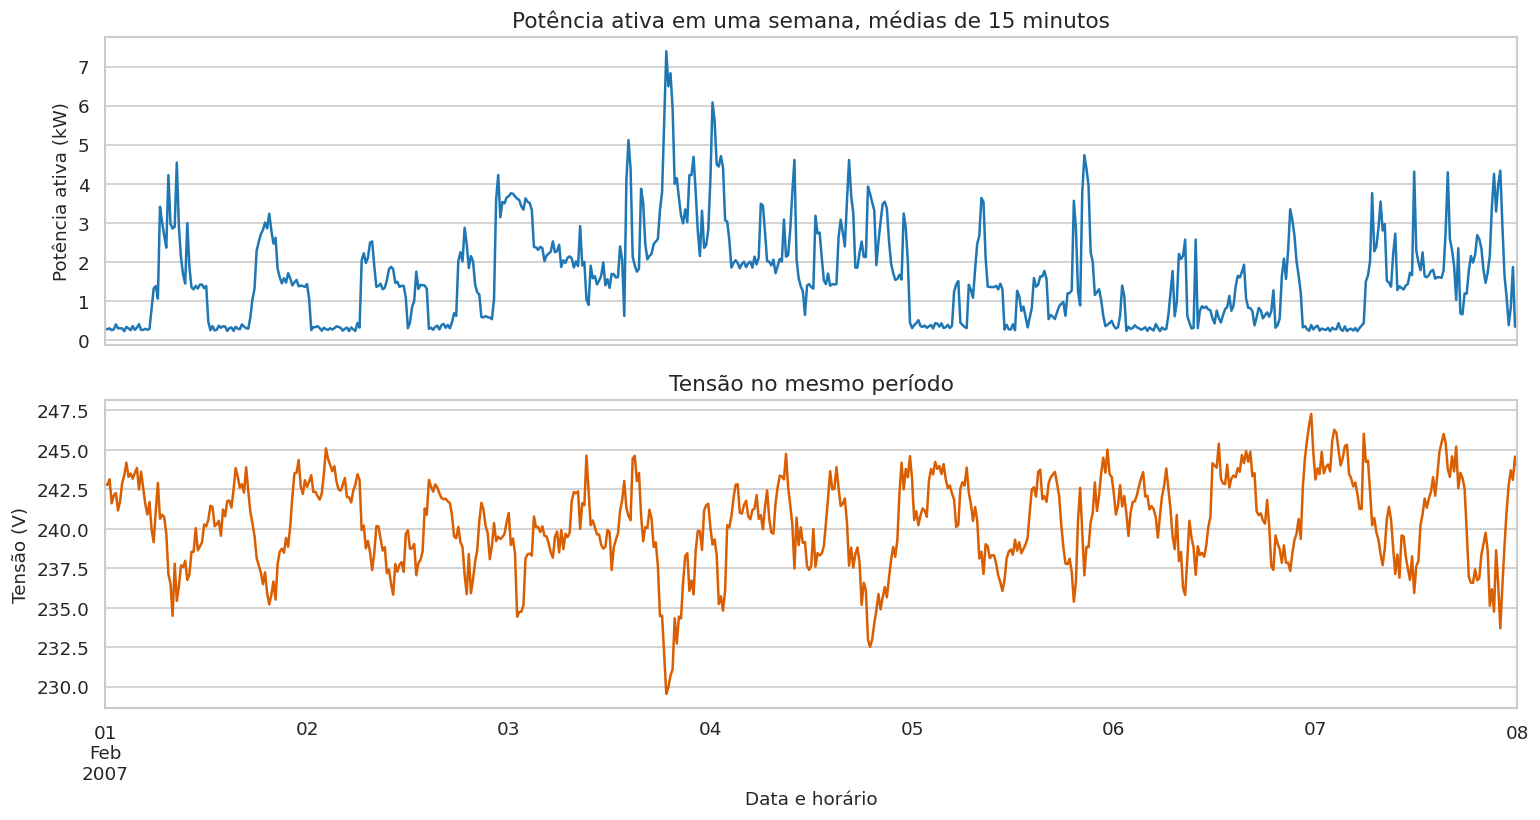

In [ ]:
inicio_semana = pd.Timestamp("2007-02-01")
fim_semana = inicio_semana + pd.Timedelta(days=7)

semana = (
    dados_limpos
    .set_index("data_hora")
    .loc[inicio_semana:fim_semana, ["potencia_ativa_global_kW", "tensao_V"]]
    .resample("15min")
    .mean()
)

fig, eixos = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
semana["potencia_ativa_global_kW"].plot(ax=eixos[0], color="#1f77b4")
eixos[0].set_title("Potência ativa em uma semana, médias de 15 minutos")
eixos[0].set_ylabel("Potência ativa (kW)")

semana["tensao_V"].plot(ax=eixos[1], color="#d95f02")
eixos[1].set_title("Tensão no mesmo período")
eixos[1].set_ylabel("Tensão (V)")
eixos[1].set_xlabel("Data e horário")

plt.tight_layout()
plt.show()


### Leitura do gráfico semanal

O gráfico superior permite observar a sucessão de vales e picos. Os picos não ocorrem necessariamente no mesmo horário nem possuem a mesma intensidade. Essa variação motiva a procura por tipos de dia.

O gráfico inferior apresenta a tensão na mesma janela. Uma associação visual entre carga e tensão pode ser investigada, mas o gráfico isolado não demonstra causalidade. Outras cargas, características da rede, regulação e condições de medição também influenciam a tensão.


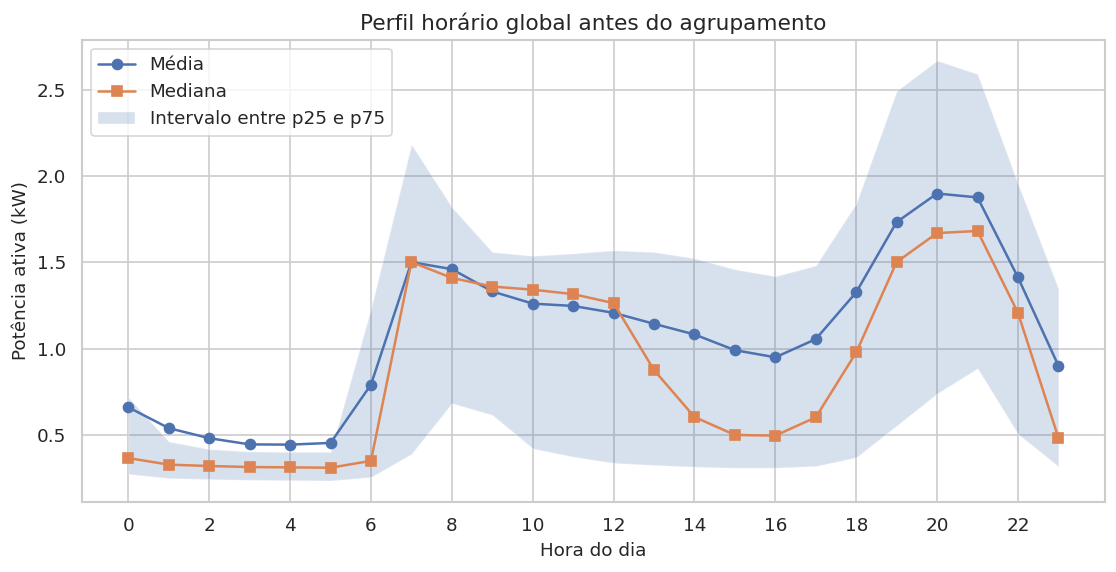

In [ ]:
dados_limpos["hora"] = dados_limpos["data_hora"].dt.hour

perfil_horario = (
    dados_limpos.groupby("hora")["potencia_ativa_global_kW"]
    .agg(
        media="mean",
        mediana="median",
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
    )
)

plt.figure(figsize=(11, 5))
plt.plot(perfil_horario.index, perfil_horario["media"], marker="o", label="Média")
plt.plot(perfil_horario.index, perfil_horario["mediana"], marker="s", label="Mediana")
plt.fill_between(
    perfil_horario.index,
    perfil_horario["p25"],
    perfil_horario["p75"],
    alpha=0.22,
    label="Intervalo entre p25 e p75",
)
plt.xticks(range(0, 24, 2))
plt.xlabel("Hora do dia")
plt.ylabel("Potência ativa (kW)")
plt.title("Perfil horário global antes do agrupamento")
plt.legend()
plt.show()


### Limitação da média global

O perfil horário global mistura dias úteis, fins de semana, estações do ano e níveis de consumo diferentes. Uma curva média pode não representar nenhum dia real. O agrupamento será empregado para substituir uma única média por várias curvas representativas.

A faixa entre os percentis 25% e 75% mostra a dispersão central. Uma faixa larga indica que o mesmo horário pode apresentar comportamentos bastante distintos em dias diferentes.


## 8. Engenharia de atributos

Engenharia de atributos é a transformação das medições originais em descrições adequadas ao problema. O algoritmo não entende os conceitos de pico, fator de carga ou consumo noturno se essas informações não forem representadas numericamente.

Cada dia será convertido em uma linha. Essa decisão define a unidade de análise. Se cada minuto fosse uma linha, os grupos descreveriam estados instantâneos. Se cada residência fosse uma linha, os grupos descreveriam consumidores. Aqui, os grupos descreverão dias.


### 8.1 Grandezas derivadas em cada minuto

Serão calculadas:

* energia ativa total do minuto, em kWh;
* energias dos circuitos submedidos, convertidas de Wh para kWh;
* energia residual de outros equipamentos;
* fator de potência aproximado;
* período do dia.

O fator de potência será aproximado por:

\[
FP = \frac{P}{\sqrt{P^2 + Q^2}}
\]

Essa expressão assume compatibilidade entre as grandezas agregadas P e Q. O resultado é útil para exploração, mas não substitui uma análise de qualidade de energia com formas de onda, harmônicos e defasagem medidos adequadamente.


In [ ]:
dados_limpos["energia_total_minuto_kWh"] = (
    dados_limpos["potencia_ativa_global_kW"] / 60
)
dados_limpos["energia_cozinha_minuto_kWh"] = (
    dados_limpos["energia_cozinha_Wh"] / 1000
)
dados_limpos["energia_lavanderia_minuto_kWh"] = (
    dados_limpos["energia_lavanderia_Wh"] / 1000
)
dados_limpos["energia_aquecimento_climatizacao_minuto_kWh"] = (
    dados_limpos["energia_aquecimento_climatizacao_Wh"] / 1000
)

energia_submedida_Wh = (
    dados_limpos["energia_cozinha_Wh"]
    + dados_limpos["energia_lavanderia_Wh"]
    + dados_limpos["energia_aquecimento_climatizacao_Wh"]
)
energia_total_Wh = dados_limpos["potencia_ativa_global_kW"] * 1000 / 60
dados_limpos["energia_outros_Wh_bruta"] = energia_total_Wh - energia_submedida_Wh

quantidade_residuos_negativos = int(
    (dados_limpos["energia_outros_Wh_bruta"] < 0).sum()
)
dados_limpos["energia_outros_minuto_kWh"] = (
    dados_limpos["energia_outros_Wh_bruta"].clip(lower=0) / 1000
)

potencia_aparente_aproximada = np.sqrt(
    dados_limpos["potencia_ativa_global_kW"] ** 2
    + dados_limpos["potencia_reativa_global_kvar"] ** 2
)
dados_limpos["fator_potencia_aproximado"] = np.where(
    potencia_aparente_aproximada > 0,
    dados_limpos["potencia_ativa_global_kW"] / potencia_aparente_aproximada,
    np.nan,
)

dados_limpos["periodo_dia"] = pd.cut(
    dados_limpos["hora"],
    bins=[-1, 5, 11, 17, 23],
    labels=["madrugada", "manha", "tarde", "noite"],
)

print("Resíduos negativos antes do ajuste:", quantidade_residuos_negativos)
print("Fator de potência aproximado mínimo:",
      round(float(np.nanmin(dados_limpos["fator_potencia_aproximado"])), 4))
print("Fator de potência aproximado máximo:",
      round(float(np.nanmax(dados_limpos["fator_potencia_aproximado"])), 4))


Resíduos negativos antes do ajuste: 1048
Fator de potência aproximado mínimo: 0.5559
Fator de potência aproximado máximo: 1.0


### Interpretação das verificações

A energia residual é uma diferença entre a estimativa total e três medidores parciais. Pequenos valores negativos podem surgir por arredondamento, sincronização e resolução dos sensores. Neste exercício, esses valores são limitados a zero antes da agregação.

O fator de potência aproximado deve permanecer entre zero e um. Valores próximos de um indicam menor participação relativa de potência reativa nessa aproximação. Esse valor não deve ser tratado como diagnóstico normativo da instalação.


### 8.2 Agregação diária

Para cada dia serão calculados indicadores de quantidade, intensidade, forma e qualidade:

* energia total;
* potência média e demanda de pico;
* percentis 5% e 95%;
* desvio padrão e coeficiente de variação;
* fator de carga;
* potência reativa média;
* fator de potência médio;
* tensão média e dispersão da tensão;
* corrente média e máxima;
* energia e participação por circuito;
* participação da energia em quatro períodos do dia;
* horário de maior potência média horária.


In [ ]:
agrupado_dia = dados_limpos.groupby("data", observed=True)

atributos_diarios = agrupado_dia.agg(
    energia_total_kWh=("energia_total_minuto_kWh", "sum"),
    demanda_media_kW=("potencia_ativa_global_kW", "mean"),
    demanda_pico_kW=("potencia_ativa_global_kW", "max"),
    potencia_p05_kW=("potencia_ativa_global_kW", lambda x: x.quantile(0.05)),
    potencia_p95_kW=("potencia_ativa_global_kW", lambda x: x.quantile(0.95)),
    desvio_potencia_kW=("potencia_ativa_global_kW", "std"),
    reativa_media_kvar=("potencia_reativa_global_kvar", "mean"),
    fator_potencia_medio=("fator_potencia_aproximado", "mean"),
    tensao_media_V=("tensao_V", "mean"),
    tensao_desvio_V=("tensao_V", "std"),
    tensao_minima_V=("tensao_V", "min"),
    tensao_maxima_V=("tensao_V", "max"),
    corrente_media_A=("corrente_global_A", "mean"),
    corrente_pico_A=("corrente_global_A", "max"),
    energia_cozinha_kWh=("energia_cozinha_minuto_kWh", "sum"),
    energia_lavanderia_kWh=("energia_lavanderia_minuto_kWh", "sum"),
    energia_aquecimento_climatizacao_kWh=(
        "energia_aquecimento_climatizacao_minuto_kWh",
        "sum",
    ),
    energia_outros_kWh=("energia_outros_minuto_kWh", "sum"),
)

atributos_diarios["fator_carga"] = (
    atributos_diarios["demanda_media_kW"]
    / atributos_diarios["demanda_pico_kW"]
)
atributos_diarios["coeficiente_variacao"] = (
    atributos_diarios["desvio_potencia_kW"]
    / atributos_diarios["demanda_media_kW"]
)
atributos_diarios["amplitude_central_kW"] = (
    atributos_diarios["potencia_p95_kW"]
    - atributos_diarios["potencia_p05_kW"]
)

energia_por_periodo = (
    dados_limpos
    .pivot_table(
        index="data",
        columns="periodo_dia",
        values="energia_total_minuto_kWh",
        aggfunc="sum",
        observed=True,
    )
    .rename(columns={
        "madrugada": "energia_madrugada_kWh",
        "manha": "energia_manha_kWh",
        "tarde": "energia_tarde_kWh",
        "noite": "energia_noite_kWh",
    })
)
atributos_diarios = atributos_diarios.join(energia_por_periodo)

for periodo in ["madrugada", "manha", "tarde", "noite"]:
    atributos_diarios[f"fracao_{periodo}"] = (
        atributos_diarios[f"energia_{periodo}_kWh"]
        / atributos_diarios["energia_total_kWh"]
    )

atributos_diarios["fracao_cozinha"] = (
    atributos_diarios["energia_cozinha_kWh"]
    / atributos_diarios["energia_total_kWh"]
)
atributos_diarios["fracao_lavanderia"] = (
    atributos_diarios["energia_lavanderia_kWh"]
    / atributos_diarios["energia_total_kWh"]
)
atributos_diarios["fracao_aquecimento_climatizacao"] = (
    atributos_diarios["energia_aquecimento_climatizacao_kWh"]
    / atributos_diarios["energia_total_kWh"]
)
atributos_diarios["fracao_outros"] = (
    atributos_diarios["energia_outros_kWh"]
    / atributos_diarios["energia_total_kWh"]
)

potencia_por_hora = (
    dados_limpos
    .pivot_table(
        index="data",
        columns="hora",
        values="potencia_ativa_global_kW",
        aggfunc="mean",
    )
)
atributos_diarios["hora_pico"] = potencia_por_hora.idxmax(axis=1)

atributos_diarios["dia_semana_num"] = atributos_diarios.index.dayofweek
atributos_diarios["fim_de_semana"] = (
    atributos_diarios["dia_semana_num"] >= 5
).astype(int)
atributos_diarios["mes"] = atributos_diarios.index.month

nomes_dias = {
    0: "segunda",
    1: "terca",
    2: "quarta",
    3: "quinta",
    4: "sexta",
    5: "sabado",
    6: "domingo",
}
atributos_diarios["dia_semana"] = (
    atributos_diarios["dia_semana_num"].map(nomes_dias)
)

def definir_estacao(mes):
    if mes in [12, 1, 2]:
        return "inverno"
    if mes in [3, 4, 5]:
        return "primavera"
    if mes in [6, 7, 8]:
        return "verao"
    return "outono"

atributos_diarios["estacao"] = atributos_diarios["mes"].map(definir_estacao)

atributos_diarios = atributos_diarios.replace([np.inf, -np.inf], np.nan)
print("Dimensão da tabela diária:", atributos_diarios.shape)
display(atributos_diarios.head().round(3))


Dimensão da tabela diária: (1417, 39)


,energia_total_kWh,demanda_media_kW,demanda_pico_kW,potencia_p05_kW,potencia_p95_kW,desvio_potencia_kW,reativa_media_kvar,fator_potencia_medio,tensao_media_V,tensao_desvio_V,...,fracao_cozinha,fracao_lavanderia,fracao_aquecimento_climatizacao,fracao_outros,hora_pico,dia_semana_num,fim_de_semana,mes,dia_semana,estacao
data,,,,,,,,,,,,,,,,,,,,,
2006-12-17,56.507999,2.354,7.064,0.336,4.449,1.206,0.157,0.988,240.087006,4.051,...,0.036,0.074,0.236,0.654,18,6,1,12,domingo,inverno
2006-12-18,36.730000,1.530,6.158,0.212,3.419,1.005,0.112,0.977,241.231995,3.720,...,0.029,0.071,0.382,0.518,20,0,0,12,segunda,inverno
2006-12-19,27.770000,1.157,7.840,0.230,3.705,1.238,0.105,0.973,241.998993,3.069,...,0.030,0.274,0.223,0.473,8,1,0,12,terca,inverno
2006-12-20,37.096001,1.546,5.988,0.208,3.696,1.321,0.112,0.979,242.307999,3.346,...,0.000,0.071,0.379,0.550,21,2,0,12,quarta,inverno
2006-12-21,28.618999,1.192,5.854,0.206,3.314,0.993,0.100,0.980,241.042007,3.700,...,0.062,0.092,0.364,0.483,9,3,0,12,quinta,inverno


### O que mudou após a agregação?

Antes, uma linha representava um minuto. Agora, uma linha representa um dia. A quantidade de linhas diminuiu fortemente, enquanto o significado de cada linha ficou alinhado ao problema de segmentação diária.

Alguns atributos carregam informação semelhante. Energia total e potência média, por exemplo, são diretamente relacionadas quando todos os dias possuem 24 horas. Inserir ambas no agrupamento daria peso duplicado à mesma dimensão. Por isso, nem toda coluna calculada será entregue ao algoritmo.


### 8.3 Seleção consciente dos atributos de agrupamento

Serão utilizadas 14 características:

| Dimensão | Atributos |
|---|---|
| quantidade de energia | energia total |
| intensidade e forma | demanda de pico, fator de carga, coeficiente de variação |
| comportamento elétrico | potência reativa média, fator de potência médio, tensão média, desvio da tensão |
| distribuição temporal | frações de madrugada, manhã e tarde |
| distribuição por uso | frações de cozinha, lavanderia e aquecimento/climatização |

A fração noturna e a fração de outros equipamentos não entram porque cada conjunto de frações soma aproximadamente um. Quando três frações temporais são conhecidas, a quarta pode ser deduzida. A mesma lógica se aplica às frações por circuito.

Variáveis de calendário, como mês e fim de semana, também não entram. Elas serão utilizadas depois para verificar se os grupos possuem relação com contextos conhecidos, sem obrigar o algoritmo a separar os dias por calendário.


In [ ]:
ATRIBUTOS_MODELO = [
    "energia_total_kWh",
    "demanda_pico_kW",
    "fator_carga",
    "coeficiente_variacao",
    "reativa_media_kvar",
    "fator_potencia_medio",
    "tensao_media_V",
    "tensao_desvio_V",
    "fracao_madrugada",
    "fracao_manha",
    "fracao_tarde",
    "fracao_cozinha",
    "fracao_lavanderia",
    "fracao_aquecimento_climatizacao",
]

antes = len(atributos_diarios)
atributos_diarios = atributos_diarios.dropna(subset=ATRIBUTOS_MODELO).copy()
depois = len(atributos_diarios)

X_original = atributos_diarios[ATRIBUTOS_MODELO].copy()

print("Dias antes da verificação final:", antes)
print("Dias utilizados no agrupamento:", depois)
print("Dias removidos nesta etapa:", antes - depois)
display(X_original.describe().T.round(4))


Dias antes da verificação final: 1417
Dias utilizados no agrupamento: 1417
Dias removidos nesta etapa: 0


,count,mean,std,min,25%,50%,75%,max
energia_total_kWh,1417.0,26.1994,10.0029,4.1716,19.6623,25.9376,31.6750,79.5564
demanda_pico_kW,1417.0,5.3942,1.6748,0.9120,4.4860,5.4600,6.3620,11.1220
fator_carga,1417.0,0.2049,0.0515,0.0711,0.1700,0.2007,0.2381,0.5365
coeficiente_variacao,1417.0,0.8687,0.1627,0.3505,0.7665,0.8557,0.9553,1.5415
reativa_media_kvar,1417.0,0.1237,0.0340,0.0578,0.0991,0.1189,0.1414,0.2902
fator_potencia_medio,1417.0,0.9637,0.0287,0.8233,0.9533,0.9745,0.9828,0.9982
tensao_media_V,1417.0,240.8408,2.0330,231.0882,240.0945,240.9736,241.8711,247.4350
tensao_desvio_V,1417.0,2.4284,0.6928,1.0439,1.9089,2.3286,2.8953,5.9679
fracao_madrugada,1417.0,0.1252,0.0709,0.0380,0.0789,0.1028,0.1423,0.5385
fracao_manha,1417.0,0.2957,0.0876,0.0465,0.2308,0.3004,0.3604,0.6086


### Leitura da matriz de entrada

A variável X_original é a matriz que descreve os dias. Ela possui uma linha por dia e 14 colunas. Não existe uma variável alvo y.

A tabela descritiva permite comparar amplitudes. Tensão média pode estar na ordem de centenas, fator de carga entre zero e um, e energia em dezenas de kWh. Essa diferença será decisiva no cálculo de distâncias.


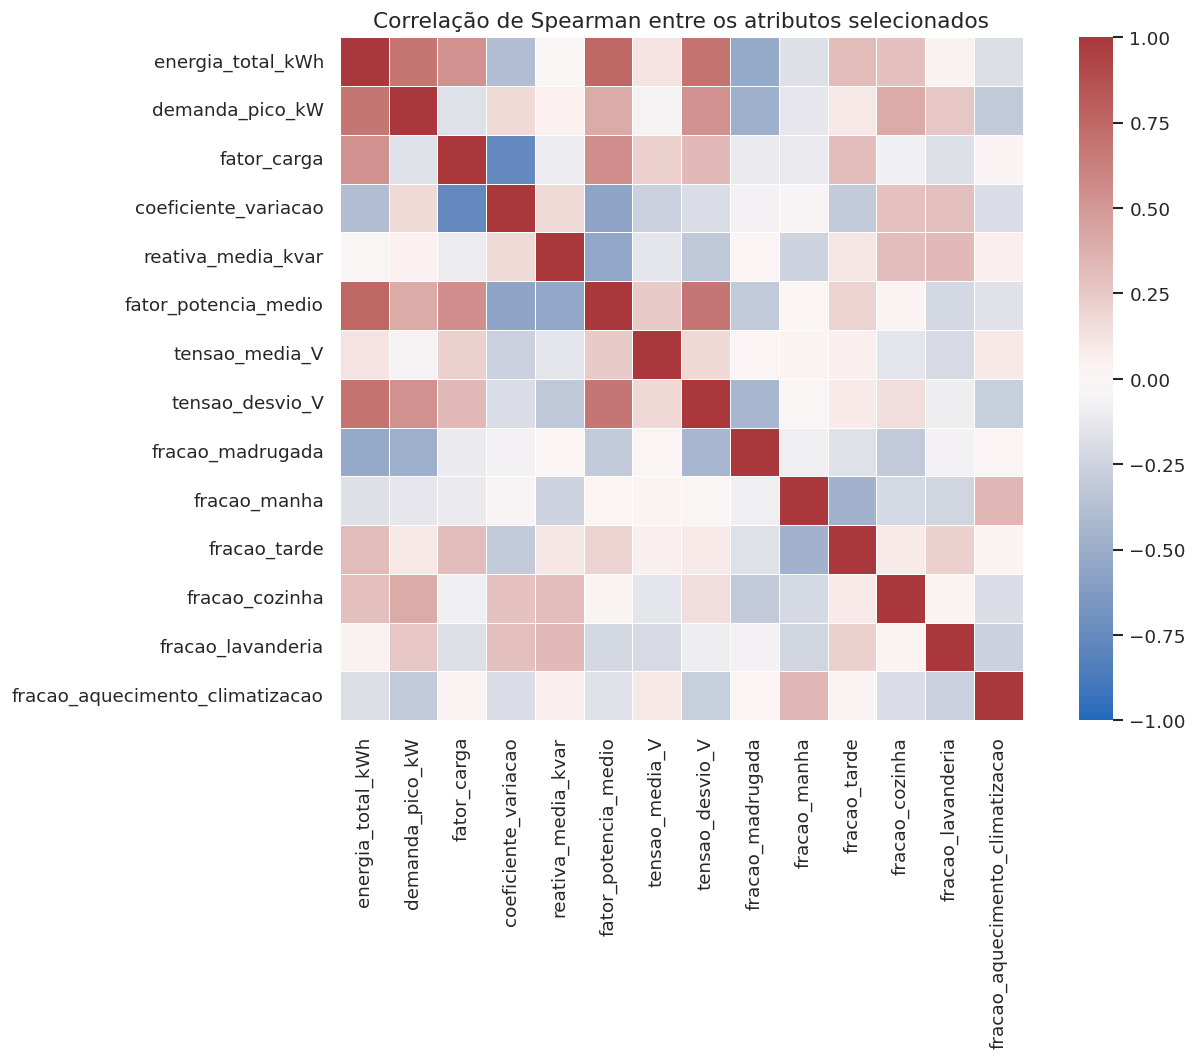

correlacao  valor_absoluto
fator_carga          coeficiente_variacao      -0.762           0.762
energia_total_kWh    fator_potencia_medio       0.753           0.753
                     tensao_desvio_V            0.694           0.694
                     demanda_pico_kW            0.682           0.682
fator_potencia_medio tensao_desvio_V            0.673           0.673
coeficiente_variacao fator_potencia_medio      -0.555           0.555
reativa_media_kvar   fator_potencia_medio      -0.545           0.545
fator_carga          fator_potencia_medio       0.545           0.545
energia_total_kWh    fator_carga                0.535           0.535
demanda_pico_kW      tensao_desvio_V            0.532           0.532

In [ ]:
correlacao = X_original.corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlacao,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
)
plt.title("Correlação de Spearman entre os atributos selecionados")
plt.tight_layout()
plt.show()

pares = (
    correlacao.where(np.triu(np.ones(correlacao.shape), k=1).astype(bool))
    .stack()
    .rename("correlacao")
    .to_frame()
)
pares["valor_absoluto"] = pares["correlacao"].abs()
display(pares.sort_values("valor_absoluto", ascending=False).head(10).round(3))


### Interpretação da correlação

A correlação de Spearman mede associação monotônica. Valores próximos de 1 indicam que duas variáveis tendem a crescer juntas. Valores próximos de menos 1 indicam movimentos opostos. Valores próximos de zero indicam ausência de relação monotônica forte.

Correlação elevada não prova redundância completa nem causalidade. Entretanto, muitas variáveis quase duplicadas podem fazer uma dimensão conceitual receber peso excessivo na distância. A matriz auxilia uma seleção de atributos fundamentada.


## 9. Distância: a base matemática do agrupamento

Muitos algoritmos comparam amostras por distância euclidiana. Para dois dias descritos por p atributos:

\[
d(\mathbf{x},\mathbf{y}) =
\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}
\]

Cada diferença é elevada ao quadrado, todas são somadas e calcula-se a raiz. Uma coluna com números numericamente grandes pode dominar a soma, mesmo quando não é conceitualmente mais importante.

A célula seguinte escolhe o dia de menor energia e o dia de maior energia e mostra quais atributos mais contribuem para a distância antes da padronização.


In [ ]:
data_menor_energia = X_original["energia_total_kWh"].idxmin()
data_maior_energia = X_original["energia_total_kWh"].idxmax()

dia_a = X_original.loc[data_menor_energia]
dia_b = X_original.loc[data_maior_energia]

contribuicao_bruta = (dia_a - dia_b) ** 2
contribuicao_bruta = (
    100 * contribuicao_bruta / contribuicao_bruta.sum()
).sort_values(ascending=False)

print("Dia de menor energia:", data_menor_energia.date())
print("Dia de maior energia:", data_maior_energia.date())
print("Distância euclidiana sem padronização:",
      round(float(np.linalg.norm(dia_a - dia_b)), 3))
display(
    contribuicao_bruta.rename("participacao_percentual_na_distancia")
    .to_frame()
    .head(8)
    .round(2)
)


Dia de menor energia: 2008-08-25
Dia de maior energia: 2006-12-23
Distância euclidiana sem padronização: 75.799


,participacao_percentual_na_distancia
energia_total_kWh,98.910004
demanda_pico_kW,1.040000
tensao_media_V,0.030000
tensao_desvio_V,0.010000
coeficiente_variacao,0.000000
fator_carga,0.000000
fracao_aquecimento_climatizacao,0.000000
fator_potencia_medio,0.000000


### Interpretação da contribuição

A participação percentual mostra quanto cada coluna respondeu pela distância quadrática entre os dois dias escolhidos. Se poucas variáveis dominarem quase toda a distância apenas por sua unidade, o algoritmo praticamente ignorará as demais.

Isso não significa que todas as variáveis devem sempre ter o mesmo peso. Significa que o peso deve resultar de uma decisão, e não apenas da unidade de medida.


## 10. Padronização

Será utilizado o StandardScaler. Para cada atributo, ele subtrai a média e divide pelo desvio padrão:

\[
z = \frac{x-\mu}{\sigma}
\]

Após a transformação, cada coluna possui média próxima de zero e desvio padrão próximo de um. Um valor z igual a 2 indica uma observação aproximadamente dois desvios acima da média daquela variável.

O escalonador deve ser ajustado apenas uma vez e preservado. Novos dias precisam receber exatamente a mesma transformação aprendida na base original.


In [ ]:
escalonador = StandardScaler()
X_padronizado = escalonador.fit_transform(X_original)

X_padronizado_df = pd.DataFrame(
    X_padronizado,
    index=X_original.index,
    columns=ATRIBUTOS_MODELO,
)

verificacao_escala = pd.DataFrame(
    {
        "media_apos_padronizacao": X_padronizado_df.mean(),
        "desvio_apos_padronizacao": X_padronizado_df.std(ddof=0),
    }
)
display(verificacao_escala.round(6))

dia_a_pad = X_padronizado_df.loc[data_menor_energia]
dia_b_pad = X_padronizado_df.loc[data_maior_energia]
contribuicao_pad = (dia_a_pad - dia_b_pad) ** 2
contribuicao_pad = (
    100 * contribuicao_pad / contribuicao_pad.sum()
).sort_values(ascending=False)

print("Distância após padronização:",
      round(float(np.linalg.norm(dia_a_pad - dia_b_pad)), 3))
display(
    contribuicao_pad.rename("participacao_percentual_na_distancia")
    .to_frame()
    .head(8)
    .round(2)
)


,media_apos_padronizacao,desvio_apos_padronizacao
energia_total_kWh,0.0,1.000000
demanda_pico_kW,0.0,1.000000
fator_carga,-0.0,1.000000
coeficiente_variacao,0.0,1.000000
reativa_media_kvar,-0.0,1.000000
fator_potencia_medio,0.0,1.000000
tensao_media_V,0.0,1.000000
tensao_desvio_V,0.0,1.000000
fracao_madrugada,-0.0,1.000000
fracao_manha,0.0,1.000000


Distância após padronização: 11.605


,participacao_percentual_na_distancia
energia_total_kWh,42.200001
fator_potencia_medio,19.160000
demanda_pico_kW,15.870000
fator_carga,11.150000
coeficiente_variacao,2.630000
fracao_aquecimento_climatizacao,2.210000
fracao_madrugada,1.980000
fracao_lavanderia,1.710000


### O que deve ser observado

As médias transformadas devem ficar muito próximas de zero e os desvios, muito próximos de um. Pequenas diferenças decorrem de precisão numérica.

A distância padronizada não pode ser comparada diretamente à distância bruta porque está em outro sistema de coordenadas. O aspecto importante é a redistribuição das contribuições. A padronização permite que atributos com unidades diferentes participem de maneira comparável.

O StandardScaler é sensível a valores extremos. Neste estudo, os picos não são removidos porque podem representar comportamento elétrico relevante. Em outra aplicação, deve-se comparar transformação robusta, análise separada de anomalias e conhecimento de domínio.


## 11. PCA: redução de dimensionalidade e visualização

A Análise de Componentes Principais cria novas direções chamadas componentes principais. A primeira componente captura a maior variância linear possível. A segunda captura a maior parte restante e é ortogonal à primeira.

O PCA não conhece grupos, dias úteis ou conceitos elétricos. Ele apenas reorganiza a variação da matriz.

Neste notebook, o PCA terá duas funções:

1. representar os 14 atributos em um gráfico bidimensional;
2. criar uma representação mais compacta para os algoritmos sensíveis à alta dimensionalidade.

Um gráfico com duas componentes perde informação. Por isso, o K-means principal será ajustado nos 14 atributos padronizados, e o PCA com duas componentes será utilizado apenas para visualizar.


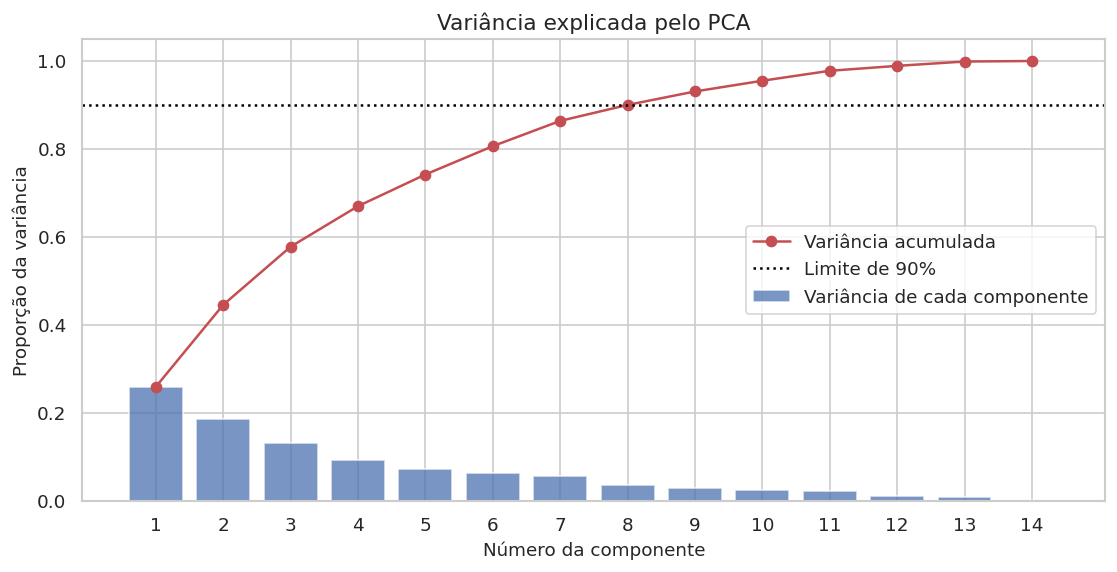

Componentes necessárias para explicar pelo menos 90% da variância: 8


,componente,variancia_explicada,variancia_acumulada
0,1,0.2596,0.2596
1,2,0.1863,0.4459
2,3,0.1321,0.5779
3,4,0.0921,0.6701
4,5,0.0720,0.7420
5,6,0.0644,0.8064
6,7,0.0574,0.8639
7,8,0.0363,0.9002


In [ ]:
pca_completo = PCA()
pca_completo.fit(X_padronizado)

variancia = pca_completo.explained_variance_ratio_
variancia_acumulada = np.cumsum(variancia)
numero_componentes_90 = int(np.argmax(variancia_acumulada >= 0.90) + 1)

tabela_variancia = pd.DataFrame(
    {
        "componente": np.arange(1, len(variancia) + 1),
        "variancia_explicada": variancia,
        "variancia_acumulada": variancia_acumulada,
    }
)

fig, eixo = plt.subplots(figsize=(11, 5))
eixo.bar(
    tabela_variancia["componente"],
    tabela_variancia["variancia_explicada"],
    alpha=0.75,
    label="Variância de cada componente",
)
eixo.plot(
    tabela_variancia["componente"],
    tabela_variancia["variancia_acumulada"],
    marker="o",
    color="#c44e52",
    label="Variância acumulada",
)
eixo.axhline(0.90, color="black", linestyle=":", label="Limite de 90%")
eixo.set_xticks(tabela_variancia["componente"])
eixo.set_xlabel("Número da componente")
eixo.set_ylabel("Proporção da variância")
eixo.set_title("Variância explicada pelo PCA")
eixo.legend()
plt.show()

print("Componentes necessárias para explicar pelo menos 90% da variância:",
      numero_componentes_90)
display(tabela_variancia.head(8).round(4))


### Como interpretar a variância explicada

A barra informa a fração de variância capturada por uma componente. A linha acumulada informa quanto foi preservado ao utilizar as primeiras componentes.

Se as duas primeiras componentes explicarem, por exemplo, 50% da variância, o gráfico bidimensional omitirá os outros 50%. Pontos visualmente próximos no gráfico podem estar separados nas dimensões não exibidas. A visualização é uma aproximação, não a definição completa dos grupos.


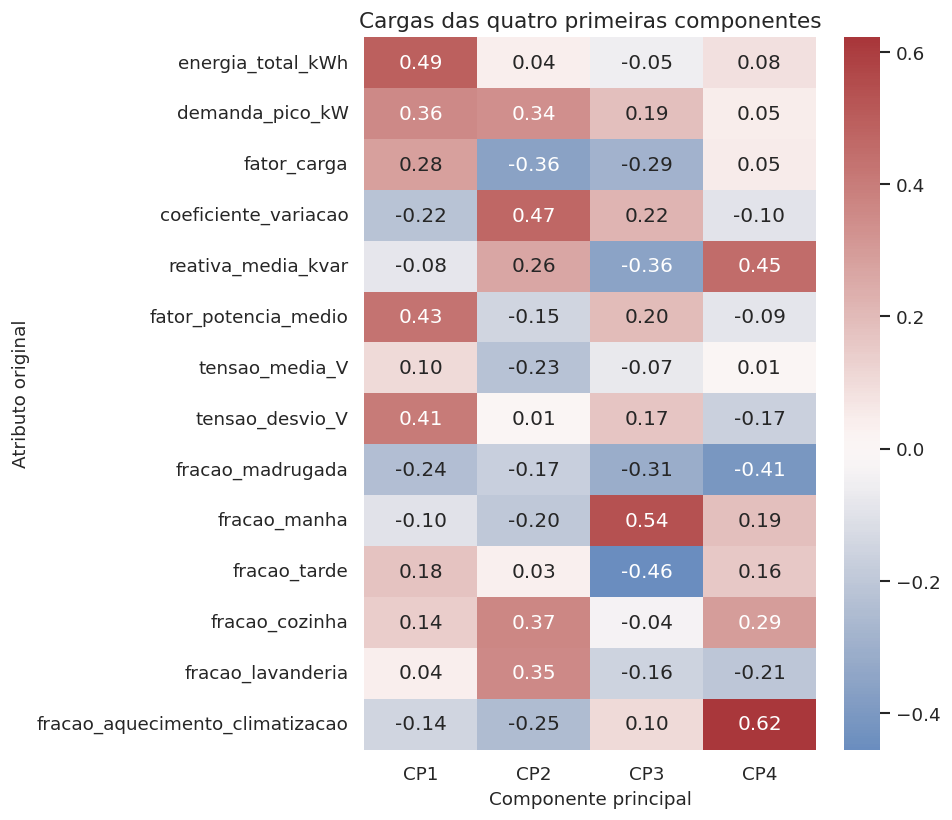

In [ ]:
pca_2d = PCA(n_components=2)
coordenadas_2d = pca_2d.fit_transform(X_padronizado)

projecao_2d = pd.DataFrame(
    coordenadas_2d,
    index=X_original.index,
    columns=["CP1", "CP2"],
)

cargas_pca = pd.DataFrame(
    pca_completo.components_[:4].T,
    index=ATRIBUTOS_MODELO,
    columns=["CP1", "CP2", "CP3", "CP4"],
)

plt.figure(figsize=(8, 7))
sns.heatmap(
    cargas_pca,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".2f",
)
plt.title("Cargas das quatro primeiras componentes")
plt.xlabel("Componente principal")
plt.ylabel("Atributo original")
plt.tight_layout()
plt.show()


### Interpretação das cargas

As cargas indicam como cada componente combina os atributos originais. Módulos elevados representam participação forte. Sinais opostos indicam que a componente contrasta variáveis.

O sinal de uma componente pode ser invertido sem alterar seu significado matemático. Portanto, o importante é a relação entre os atributos dentro da componente, e não considerar positivo como bom ou negativo como ruim.


## 12. K-means

O K-means procura K centroides e associa cada amostra ao centroide mais próximo. Seu objetivo é minimizar a soma das distâncias quadráticas internas:

\[
J = \sum_{k=1}^{K}\sum_{\mathbf{x}_i \in C_k}
\|\mathbf{x}_i-\boldsymbol{\mu}_k\|^2
\]

O funcionamento pode ser dividido em quatro passos:

1. inicializar K centroides;
2. associar cada dia ao centroide mais próximo;
3. recalcular cada centroide pela média dos dias associados;
4. repetir associação e atualização até estabilizar.

O algoritmo favorece grupos aproximadamente compactos e convexos no espaço utilizado. Ele exige K antecipadamente e pode convergir para soluções locais. Por isso, será utilizada inicialização K-means++ e múltiplas inicializações.


### 12.1 Como escolher K

Serão testados valores de 2 a 8. Quatro medidas serão observadas:

| Medida | Leitura |
|---|---|
| Inércia | soma das distâncias quadráticas internas, menor é melhor, mas sempre diminui quando K cresce |
| Silhueta | combina coesão e separação, varia aproximadamente de menos 1 a 1, maior é melhor |
| Davies-Bouldin | compara dispersão interna e separação entre grupos, menor é melhor |
| Calinski-Harabasz | razão entre dispersão entre grupos e dentro dos grupos, maior é melhor |

Nenhuma medida determina sozinha o número verdadeiro de grupos. O número final deve equilibrar qualidade interna, estabilidade, simplicidade e utilidade elétrica.


,k,inercia,silhueta,davies_bouldin,calinski_harabasz
0,2,16461.1738,0.1654,2.0952,290.271301
1,3,14591.4062,0.1428,1.9570,254.214706
2,4,13161.5293,0.1545,1.7913,238.924896
3,5,12364.0156,0.1403,1.8658,213.386505
4,6,11763.0898,0.1414,1.8104,193.719406
5,7,11200.9199,0.1234,1.8332,181.209702
6,8,10688.3945,0.1278,1.7566,172.306702


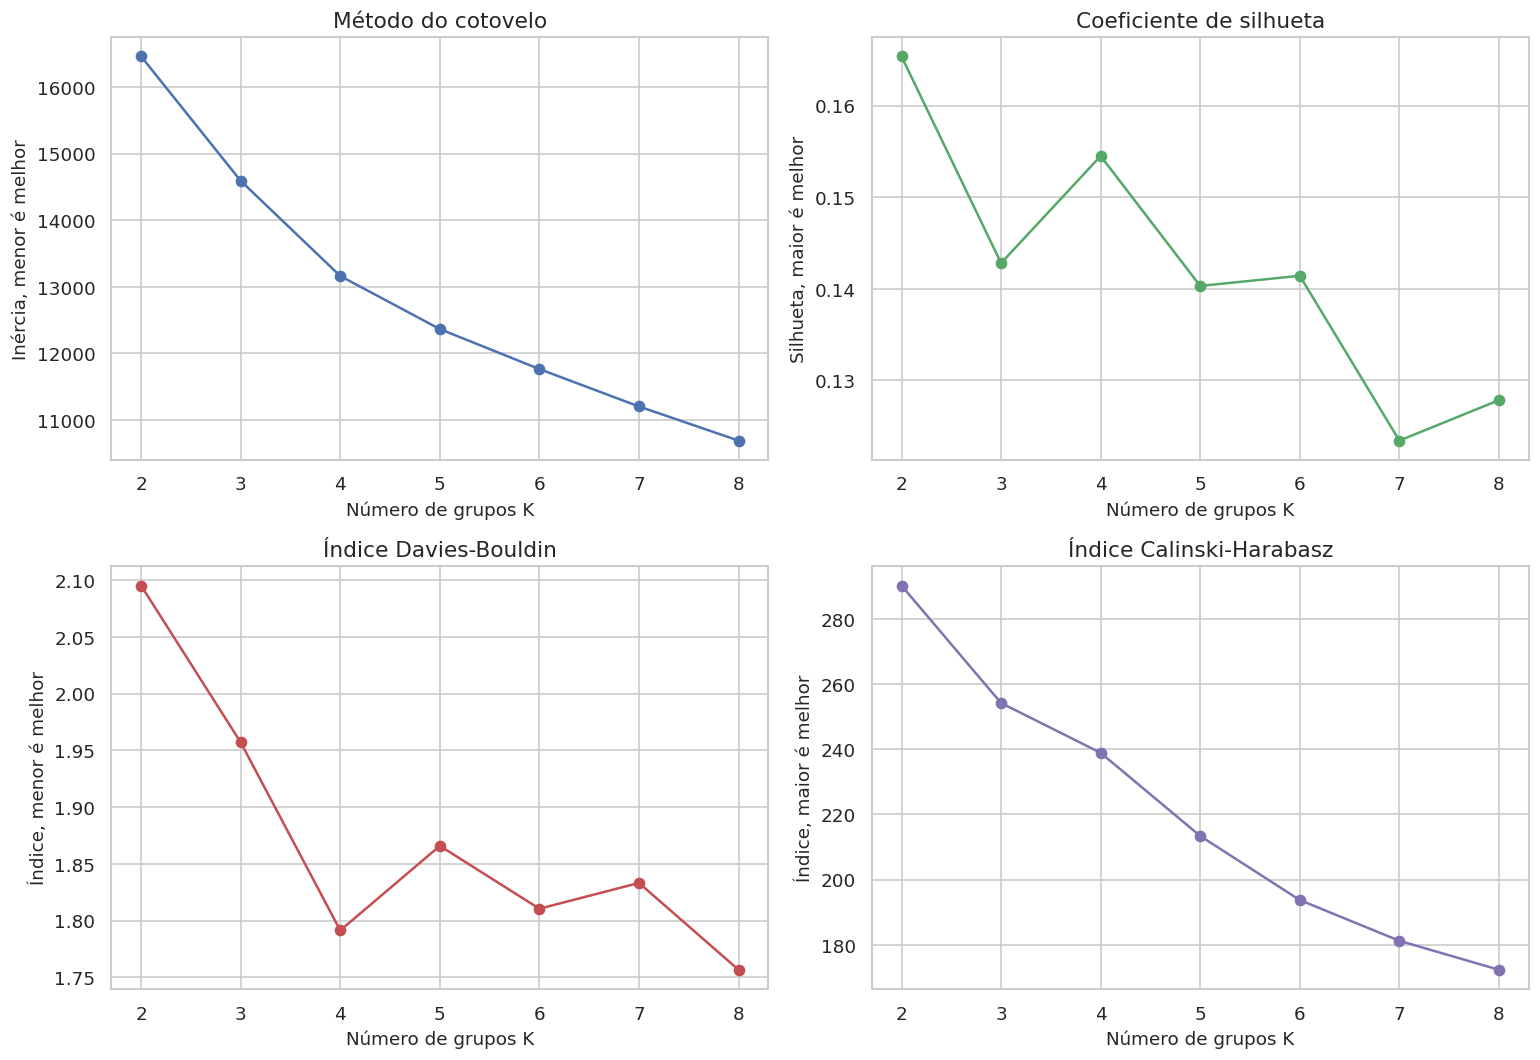

In [ ]:
resultados_k = []
modelos_k = {}

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=30,
        max_iter=500,
        random_state=SEMENTE,
    )
    rotulos = modelo.fit_predict(X_padronizado)
    modelos_k[k] = modelo

    resultados_k.append(
        {
            "k": k,
            "inercia": modelo.inertia_,
            "silhueta": silhouette_score(X_padronizado, rotulos),
            "davies_bouldin": davies_bouldin_score(X_padronizado, rotulos),
            "calinski_harabasz": calinski_harabasz_score(
                X_padronizado,
                rotulos,
            ),
        }
    )

avaliacao_k = pd.DataFrame(resultados_k)
display(avaliacao_k.round(4))

fig, eixos = plt.subplots(2, 2, figsize=(13, 9))

eixos[0, 0].plot(avaliacao_k["k"], avaliacao_k["inercia"], marker="o")
eixos[0, 0].set_title("Método do cotovelo")
eixos[0, 0].set_ylabel("Inércia, menor é melhor")

eixos[0, 1].plot(
    avaliacao_k["k"],
    avaliacao_k["silhueta"],
    marker="o",
    color="#55a868",
)
eixos[0, 1].set_title("Coeficiente de silhueta")
eixos[0, 1].set_ylabel("Silhueta, maior é melhor")

eixos[1, 0].plot(
    avaliacao_k["k"],
    avaliacao_k["davies_bouldin"],
    marker="o",
    color="#c44e52",
)
eixos[1, 0].set_title("Índice Davies-Bouldin")
eixos[1, 0].set_ylabel("Índice, menor é melhor")

eixos[1, 1].plot(
    avaliacao_k["k"],
    avaliacao_k["calinski_harabasz"],
    marker="o",
    color="#8172b2",
)
eixos[1, 1].set_title("Índice Calinski-Harabasz")
eixos[1, 1].set_ylabel("Índice, maior é melhor")

for eixo in eixos.flat:
    eixo.set_xlabel("Número de grupos K")
    eixo.set_xticks(avaliacao_k["k"])

plt.tight_layout()
plt.show()


### Leitura conjunta dos critérios

No gráfico da inércia, procura-se uma mudança de inclinação, chamada cotovelo. Depois desse ponto, adicionar grupos reduz pouco o erro interno.

A maior silhueta fornece uma indicação quantitativa direta, mas pode favorecer uma divisão simples demais. Davies-Bouldin e Calinski-Harabasz funcionam como evidências adicionais. Se os critérios discordarem, a discordância deve ser discutida.

A próxima célula apresenta o K de maior silhueta e também explicita uma escolha pedagógica. Nesta base, quatro grupos são mantidos como padrão para permitir a comparação de mais de dois perfis de carga. A decisão não é apresentada como superior à recomendação automática. Ela torna visível o compromisso entre separação matemática e detalhamento operacional.


In [ ]:
K_AUTOMATICO = int(
    avaliacao_k.loc[avaliacao_k["silhueta"].idxmax(), "k"]
)

# Quatro grupos são usados como escolha pedagógica documentada. Para seguir
# estritamente a maior silhueta, use K_ESCOLHIDO = K_AUTOMATICO.
K_PEDAGOGICO = 4
K_ESCOLHIDO = K_PEDAGOGICO

print("K sugerido pela maior silhueta:", K_AUTOMATICO)
print("K definido para ampliar a comparação didática:", K_PEDAGOGICO)
print("K utilizado nas próximas etapas:", K_ESCOLHIDO)
print(
    "Silhueta do K automático:",
    round(float(avaliacao_k.loc[avaliacao_k["k"] == K_AUTOMATICO, "silhueta"].iloc[0]), 4),
)
print(
    "Silhueta do K pedagógico:",
    round(float(avaliacao_k.loc[avaliacao_k["k"] == K_PEDAGOGICO, "silhueta"].iloc[0]), 4),
)


K sugerido pela maior silhueta: 2
K definido para ampliar a comparação didática: 4
K utilizado nas próximas etapas: 4
Silhueta do K automático: 0.1654
Silhueta do K pedagógico: 0.1545


### Observação sobre a escolha automática

O valor sugerido não é uma verdade escondida nos dados. Ele é o melhor segundo um critério específico entre os valores testados. Uma solução com grupos adicionais pode ser operacionalmente mais informativa mesmo com silhueta ligeiramente menor.

Neste notebook, a recomendação automática e a escolha pedagógica permanecem lado a lado. A decisão deve ser documentada com três tipos de evidência: métrica interna, estabilidade e interpretação dos perfis.


In [ ]:
modelo_kmeans = KMeans(
    n_clusters=K_ESCOLHIDO,
    init="k-means++",
    n_init=50,
    max_iter=500,
    random_state=SEMENTE,
)
rotulos_kmeans_brutos = modelo_kmeans.fit_predict(X_padronizado)

temporario = atributos_diarios[["energia_total_kWh"]].copy()
temporario["rotulo_bruto"] = rotulos_kmeans_brutos
ordem_por_energia = (
    temporario.groupby("rotulo_bruto")["energia_total_kWh"]
    .mean()
    .sort_values()
    .index
    .tolist()
)
mapa_ordem_kmeans = {
    rotulo_bruto: posicao + 1
    for posicao, rotulo_bruto in enumerate(ordem_por_energia)
}

atributos_diarios["perfil_kmeans"] = pd.Series(
    rotulos_kmeans_brutos,
    index=atributos_diarios.index,
).map(mapa_ordem_kmeans)

contagem_perfis = (
    atributos_diarios["perfil_kmeans"]
    .value_counts()
    .sort_index()
    .rename("quantidade_dias")
    .to_frame()
)
contagem_perfis["percentual"] = (
    100 * contagem_perfis["quantidade_dias"] / len(atributos_diarios)
)

print("Iterações até a convergência:", modelo_kmeans.n_iter_)
print("Silhueta da solução:",
      round(silhouette_score(X_padronizado, rotulos_kmeans_brutos), 4))
display(contagem_perfis.round(2))


Iterações até a convergência: 10
Silhueta da solução: 0.1545


,quantidade_dias,percentual
perfil_kmeans,,
1,170,12.00
2,357,25.19
3,502,35.43
4,388,27.38


### Por que os rótulos foram reorganizados?

Os rótulos originais do K-means são arbitrários. Para facilitar a exposição, os perfis foram renumerados pela energia média, do menor para o maior consumo. Assim, Perfil 1 possui a menor energia média entre os grupos desta execução.

A reorganização não altera nenhum pertencimento. Ela altera somente os nomes apresentados.

Grupos muito pequenos merecem atenção. Eles podem representar uma condição legítima rara, uma anomalia, um parâmetro inadequado ou uma divisão excessiva.


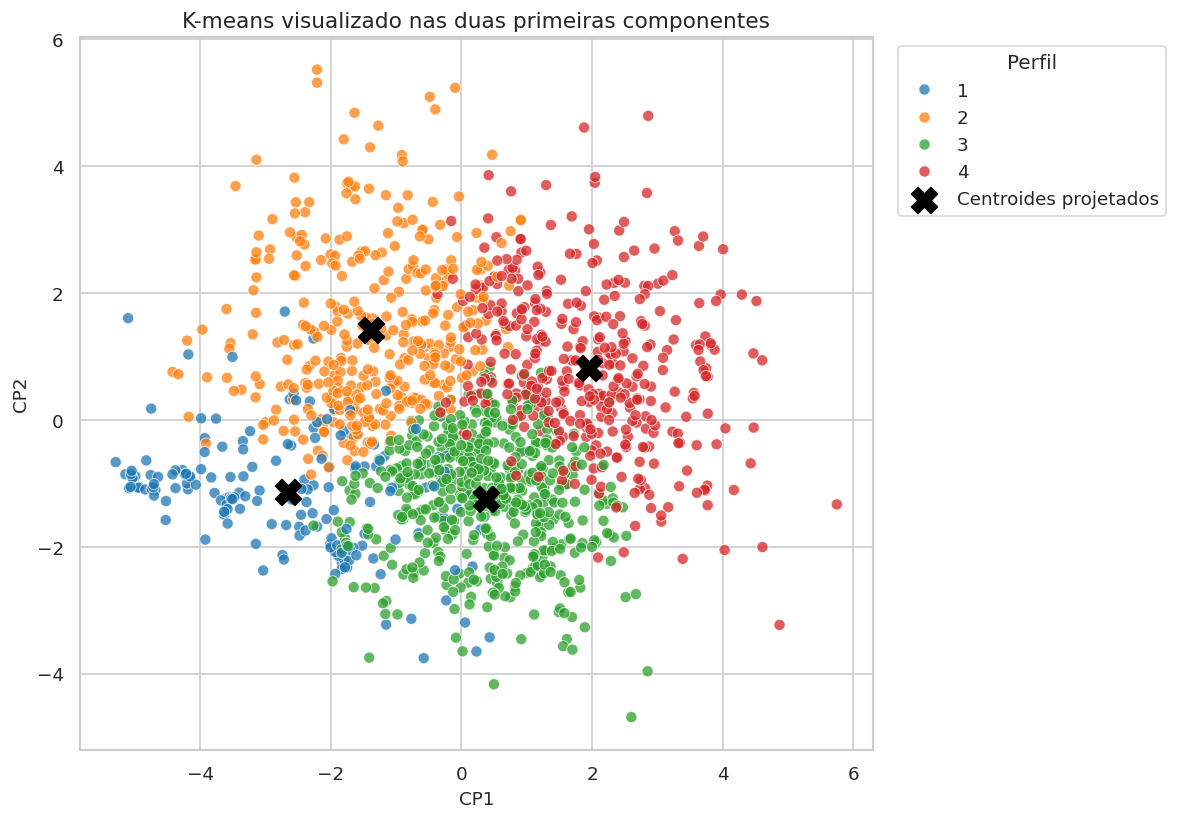

In [ ]:
projecao_kmeans = projecao_2d.copy()
projecao_kmeans["perfil"] = atributos_diarios["perfil_kmeans"]

centros_2d = pca_2d.transform(modelo_kmeans.cluster_centers_)
centros_ordenados = pd.DataFrame(
    [
        centros_2d[rotulo_bruto]
        for rotulo_bruto in ordem_por_energia
    ],
    columns=["CP1", "CP2"],
    index=range(1, K_ESCOLHIDO + 1),
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=projecao_kmeans,
    x="CP1",
    y="CP2",
    hue="perfil",
    palette="tab10",
    alpha=0.75,
    s=45,
)
plt.scatter(
    centros_ordenados["CP1"],
    centros_ordenados["CP2"],
    marker="X",
    s=240,
    c="black",
    label="Centroides projetados",
)
plt.title("K-means visualizado nas duas primeiras componentes")
plt.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Interpretação da projeção

Cada ponto é um dia. A cor é o grupo atribuído no espaço completo de 14 dimensões. Os símbolos pretos são os centroides projetados.

Sobreposições no gráfico não significam necessariamente erro. Duas amostras podem parecer próximas nas componentes 1 e 2, mas estar separadas nas componentes omitidas. A qualidade deve ser avaliada pelas métricas calculadas no espaço utilizado pelo algoritmo e pela interpretação dos atributos originais.


### 12.2 Caracterização numérica dos grupos

A média do grupo fornece um perfil central, mas pode ser influenciada por valores extremos. A mediana fornece uma descrição complementar. A tabela seguinte utiliza indicadores diretamente interpretáveis na Engenharia Elétrica.


,dias,energia_media_kWh,energia_mediana_kWh,pico_medio_kW,fator_carga_medio,variabilidade_media,reativa_media_kvar,fator_potencia_medio,tensao_media_V,tensao_desvio_V,hora_pico_mediana,fracao_noturna,percentual_fim_semana
perfil_kmeans,,,,,,,,,,,,,
1,170,12.545000,11.822,2.548,0.208,0.829,0.126,0.926,241.072006,1.704,12.0,0.266,34.706
2,357,20.364000,20.042,5.531,0.155,1.040,0.140,0.944,239.565002,2.021,20.0,0.377,22.409
3,502,26.893999,26.740,5.131,0.222,0.783,0.106,0.978,241.587997,2.558,19.0,0.332,9.163
4,388,36.653000,35.118,6.855,0.226,0.838,0.131,0.979,240.947006,2.954,18.0,0.359,55.412


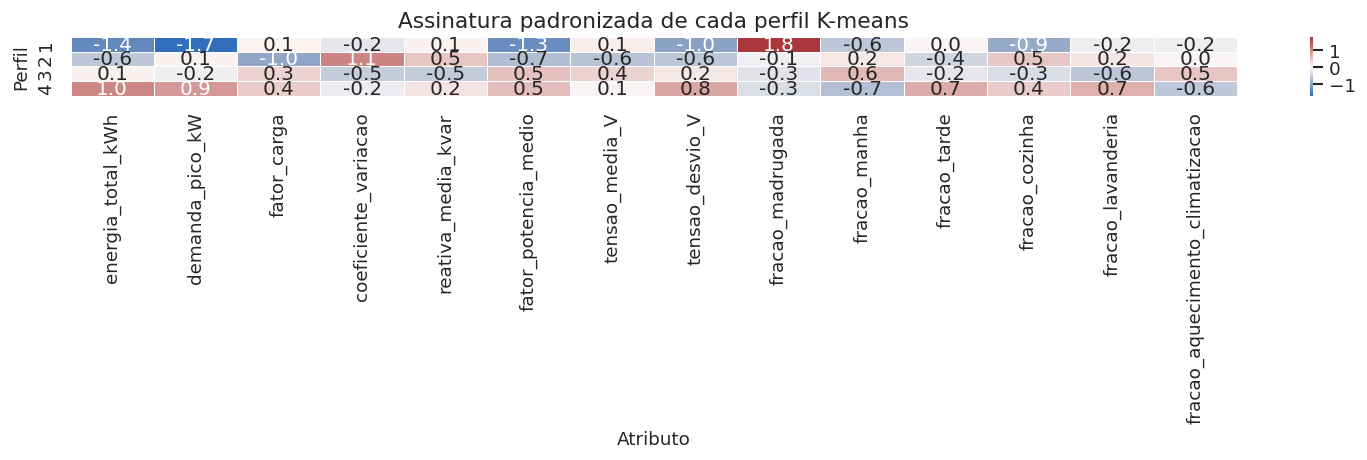

In [ ]:
resumo_kmeans = (
    atributos_diarios.groupby("perfil_kmeans")
    .agg(
        dias=("energia_total_kWh", "size"),
        energia_media_kWh=("energia_total_kWh", "mean"),
        energia_mediana_kWh=("energia_total_kWh", "median"),
        pico_medio_kW=("demanda_pico_kW", "mean"),
        fator_carga_medio=("fator_carga", "mean"),
        variabilidade_media=("coeficiente_variacao", "mean"),
        reativa_media_kvar=("reativa_media_kvar", "mean"),
        fator_potencia_medio=("fator_potencia_medio", "mean"),
        tensao_media_V=("tensao_media_V", "mean"),
        tensao_desvio_V=("tensao_desvio_V", "mean"),
        hora_pico_mediana=("hora_pico", "median"),
        fracao_noturna=("fracao_noite", "mean"),
        percentual_fim_semana=("fim_de_semana", lambda x: 100 * x.mean()),
    )
)

display(resumo_kmeans.round(3))

medias_padronizadas_por_perfil = (
    X_padronizado_df
    .assign(perfil=atributos_diarios["perfil_kmeans"])
    .groupby("perfil")
    .mean()
)

plt.figure(figsize=(13, max(4, K_ESCOLHIDO * 0.8)))
sns.heatmap(
    medias_padronizadas_por_perfil,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
)
plt.title("Assinatura padronizada de cada perfil K-means")
plt.xlabel("Atributo")
plt.ylabel("Perfil")
plt.tight_layout()
plt.show()


### Como ler o mapa de calor

Cada célula mostra a média padronizada de um atributo dentro de um perfil.

* valor próximo de zero: o grupo está próximo da média geral;
* valor positivo: o grupo está acima da média geral;
* valor negativo: o grupo está abaixo da média geral;
* módulo elevado: aquele atributo distingue fortemente o grupo.

As cores não representam qualidade. Um fator de carga abaixo da média, por exemplo, indica maior diferença relativa entre média e pico, mas sua conveniência depende do objetivo operacional.


### 12.3 Curvas de carga representativas

A caracterização mais útil para a rede elétrica é a forma temporal. As medições serão agregadas em intervalos de 15 minutos. Para cada perfil, serão calculadas a curva média e a faixa entre os percentis 25% e 75%.

Essa etapa volta aos dados por minuto e utiliza os rótulos diários. Assim, combina-se o resultado matemático do agrupamento com uma representação física familiar.


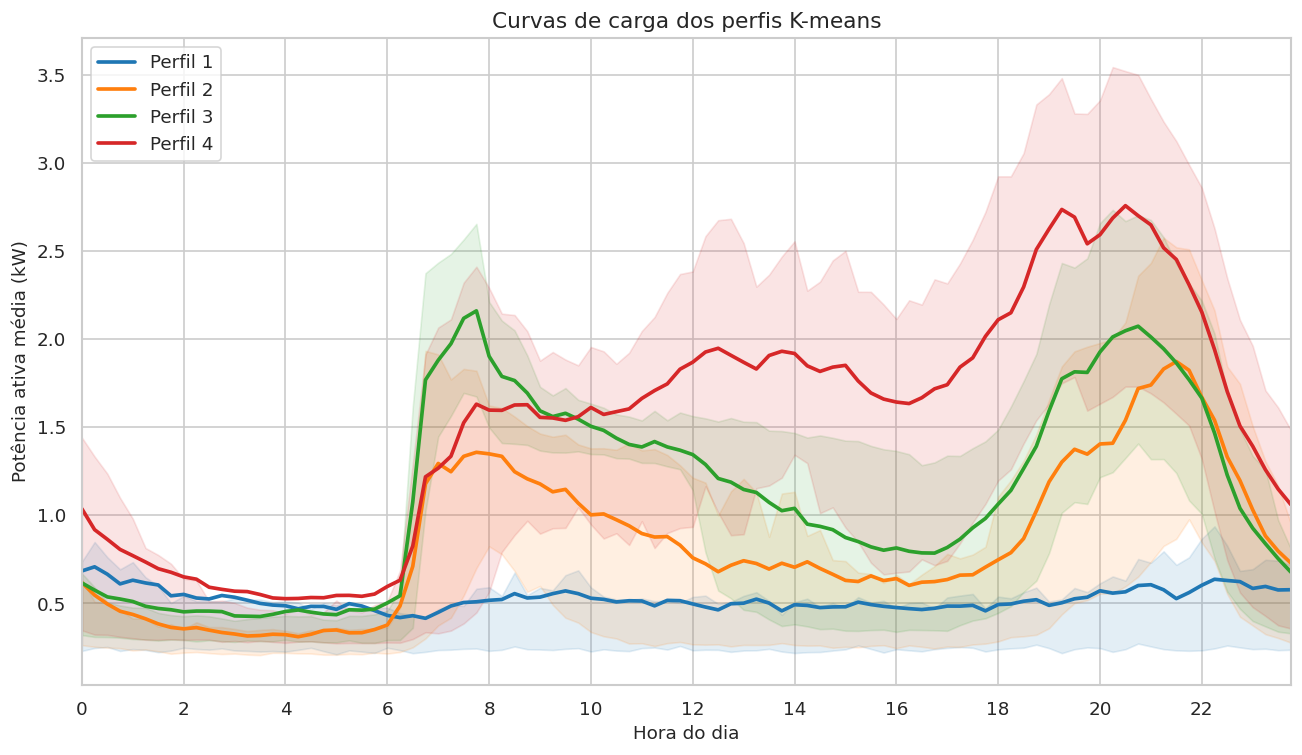

In [ ]:
dados_limpos["intervalo_15min"] = (
    dados_limpos["data_hora"].dt.hour * 4
    + dados_limpos["data_hora"].dt.minute // 15
)

perfis_15min = (
    dados_limpos
    .pivot_table(
        index="data",
        columns="intervalo_15min",
        values="potencia_ativa_global_kW",
        aggfunc="mean",
    )
    .reindex(atributos_diarios.index)
)

perfis_15min_com_grupo = perfis_15min.copy()
perfis_15min_com_grupo["perfil"] = atributos_diarios["perfil_kmeans"]

eixo_horas = np.arange(96) / 4
paleta = sns.color_palette("tab10", K_ESCOLHIDO)

plt.figure(figsize=(13, 7))
for perfil, cor in zip(range(1, K_ESCOLHIDO + 1), paleta):
    bloco = perfis_15min_com_grupo.query("perfil == @perfil").drop(
        columns="perfil"
    )
    media = bloco.mean(axis=0).to_numpy()
    p25 = bloco.quantile(0.25, axis=0).to_numpy()
    p75 = bloco.quantile(0.75, axis=0).to_numpy()

    plt.plot(eixo_horas, media, color=cor, linewidth=2.2, label=f"Perfil {perfil}")
    plt.fill_between(eixo_horas, p25, p75, color=cor, alpha=0.12)

plt.xticks(range(0, 25, 2))
plt.xlim(0, 23.75)
plt.xlabel("Hora do dia")
plt.ylabel("Potência ativa média (kW)")
plt.title("Curvas de carga dos perfis K-means")
plt.legend()
plt.show()


### Interpretação elétrica das curvas

A linha representa o comportamento médio do perfil. A faixa sombreada representa a metade central dos dias, entre os percentis 25% e 75%. Uma faixa estreita indica comportamento temporal consistente. Uma faixa larga indica que o centroide resume dias internamente variados.

Devem ser observados:

1. horário e amplitude do pico;
2. consumo de base na madrugada;
3. existência de rampas acentuadas;
4. persistência de carga ao longo do dia;
5. possibilidade de deslocamento de carga para horários menos solicitados.

A interpretação deve combinar curva, tabela de atributos e contexto. Uma curva isolada não permite identificar qual equipamento causou cada pico.


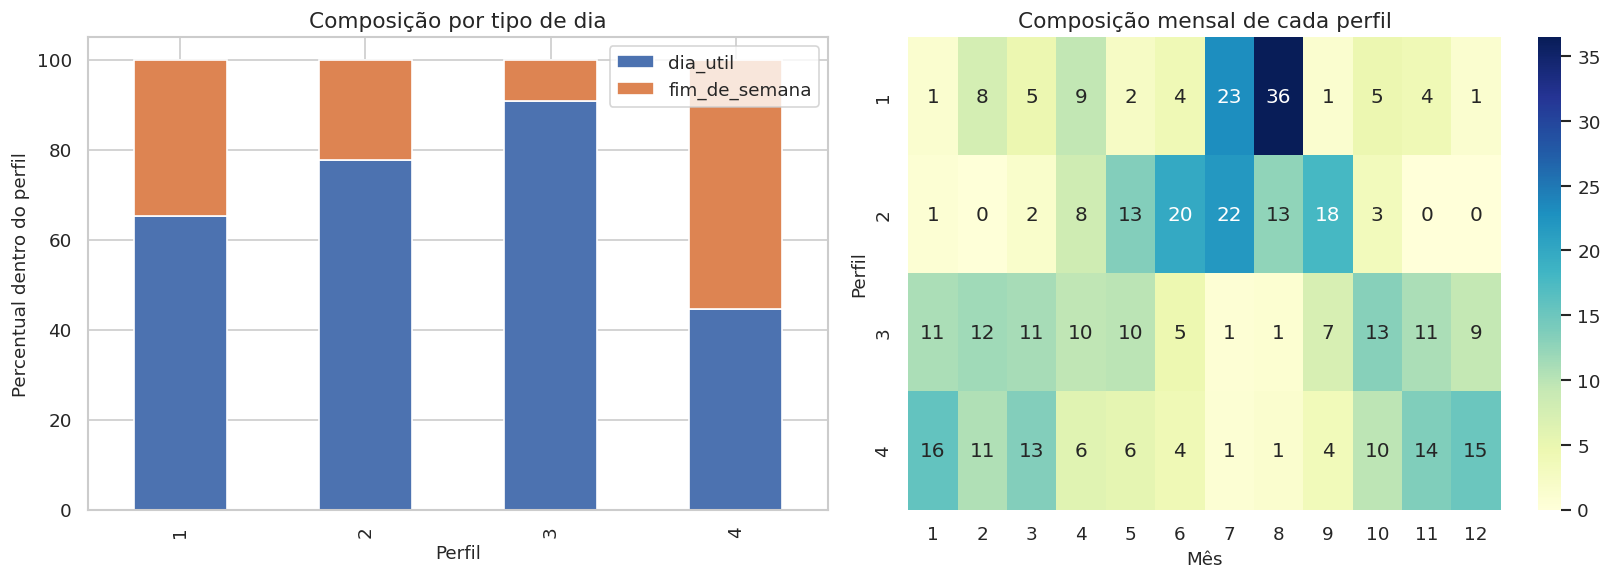

In [ ]:
distribuicao_fim_semana = pd.crosstab(
    atributos_diarios["perfil_kmeans"],
    atributos_diarios["fim_de_semana"].map({0: "dia_util", 1: "fim_de_semana"}),
    normalize="index",
) * 100

distribuicao_mensal = pd.crosstab(
    atributos_diarios["perfil_kmeans"],
    atributos_diarios["mes"],
    normalize="index",
) * 100

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
distribuicao_fim_semana.plot(
    kind="bar",
    stacked=True,
    ax=eixos[0],
    color=["#4c72b0", "#dd8452"],
)
eixos[0].set_title("Composição por tipo de dia")
eixos[0].set_xlabel("Perfil")
eixos[0].set_ylabel("Percentual dentro do perfil")
eixos[0].legend(title="")

sns.heatmap(
    distribuicao_mensal,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    ax=eixos[1],
)
eixos[1].set_title("Composição mensal de cada perfil")
eixos[1].set_xlabel("Mês")
eixos[1].set_ylabel("Perfil")

plt.tight_layout()
plt.show()


### Validação contextual

Calendário e mês não foram utilizados no agrupamento. Se um perfil apresentar concentração em determinados períodos, essa relação emergiu das grandezas elétricas.

A associação com fim de semana ou estação ajuda a produzir hipóteses. Ela não comprova causa. Temperatura, ocupação, férias, equipamentos e hábitos não foram medidos diretamente.


In [ ]:
limites_energia = atributos_diarios["energia_total_kWh"].quantile([0.33, 0.67])
limites_pico = atributos_diarios["demanda_pico_kW"].quantile([0.33, 0.67])
limite_fator = atributos_diarios["fator_carga"].median()


def nivel_relativo(valor, limites):
    if valor <= limites.iloc[0]:
        return "baixo"
    if valor <= limites.iloc[1]:
        return "intermediário"
    return "alto"


print("Síntese automática baseada em comparações relativas à própria base:\n")
for perfil, linha in resumo_kmeans.iterrows():
    nivel_energia = nivel_relativo(
        linha["energia_media_kWh"],
        limites_energia,
    )
    nivel_pico = nivel_relativo(
        linha["pico_medio_kW"],
        limites_pico,
    )
    forma = (
        "mais uniforme"
        if linha["fator_carga_medio"] >= limite_fator
        else "mais concentrada em picos"
    )

    print(
        f"Perfil {perfil}: {int(linha['dias'])} dias; "
        f"energia relativamente {nivel_energia}; "
        f"pico relativamente {nivel_pico}; "
        f"carga {forma}; "
        f"hora mediana de pico {linha['hora_pico_mediana']:.0f} h; "
        f"{linha['percentual_fim_semana']:.1f}% de fins de semana."
    )


Síntese automática baseada em comparações relativas à própria base:

Perfil 1: 170 dias; energia relativamente baixo; pico relativamente baixo; carga mais uniforme; hora mediana de pico 12 h; 34.7% de fins de semana.
Perfil 2: 357 dias; energia relativamente baixo; pico relativamente intermediário; carga mais concentrada em picos; hora mediana de pico 20 h; 22.4% de fins de semana.
Perfil 3: 502 dias; energia relativamente intermediário; pico relativamente intermediário; carga mais uniforme; hora mediana de pico 19 h; 9.2% de fins de semana.
Perfil 4: 388 dias; energia relativamente alto; pico relativamente alto; carga mais uniforme; hora mediana de pico 18 h; 55.4% de fins de semana.


### Limite da síntese automática

O texto compara cada média a quantis da própria base. Ele não conhece normas, contratos, limites térmicos, tarifa ou topologia da rede. Termos como baixo e alto são relativos somente a este conjunto.

A síntese funciona como apoio de leitura. A conclusão técnica deve ser construída a partir dos valores, das curvas e do contexto operacional.


## 13. Agrupamento hierárquico aglomerativo

O método aglomerativo começa com cada dia em seu próprio grupo. A cada etapa, os dois grupos mais próximos são unidos. O processo forma uma hierarquia.

Será utilizado o critério de Ward, que escolhe a união que produz o menor aumento possível da variância interna. Esse critério utiliza distância euclidiana e é sensível à escala, razão pela qual os dados padronizados serão empregados.

O dendrograma registra a sequência de uniões. A altura de uma união representa o aumento de distância associado à fusão. Saltos grandes podem sugerir cortes plausíveis.


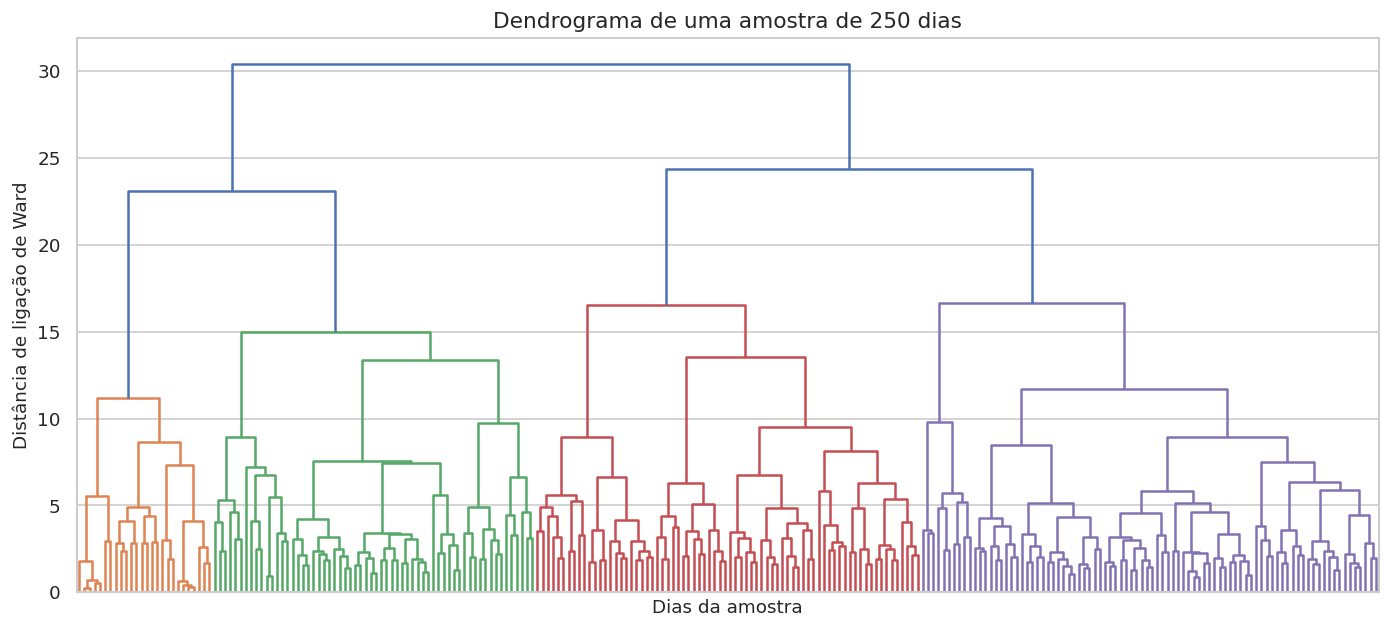

In [ ]:
gerador = np.random.default_rng(SEMENTE)
tamanho_amostra_dendrograma = min(250, len(X_padronizado))
indices_amostra = np.sort(
    gerador.choice(
        len(X_padronizado),
        size=tamanho_amostra_dendrograma,
        replace=False,
    )
)

matriz_ligacao = linkage(
    X_padronizado[indices_amostra],
    method="ward",
)

plt.figure(figsize=(14, 6))
dendrogram(
    matriz_ligacao,
    no_labels=True,
    color_threshold=None,
)
plt.title(
    f"Dendrograma de uma amostra de {tamanho_amostra_dendrograma} dias"
)
plt.xlabel("Dias da amostra")
plt.ylabel("Distância de ligação de Ward")
plt.show()


### Como ler o dendrograma

A base contém muitos dias, por isso o dendrograma utiliza uma amostra apenas para visualização. O modelo seguinte utilizará todos os dias.

Linhas verticais longas indicam uniões entre estruturas relativamente distantes. Um corte horizontal imaginário atravessa determinado número de ramos, produzindo esse número de grupos.

A ordem horizontal das folhas não representa tempo. Ela é organizada para exibir a árvore.


Silhueta do agrupamento hierárquico: 0.117
ARI entre hierárquico e K-means: 0.5028


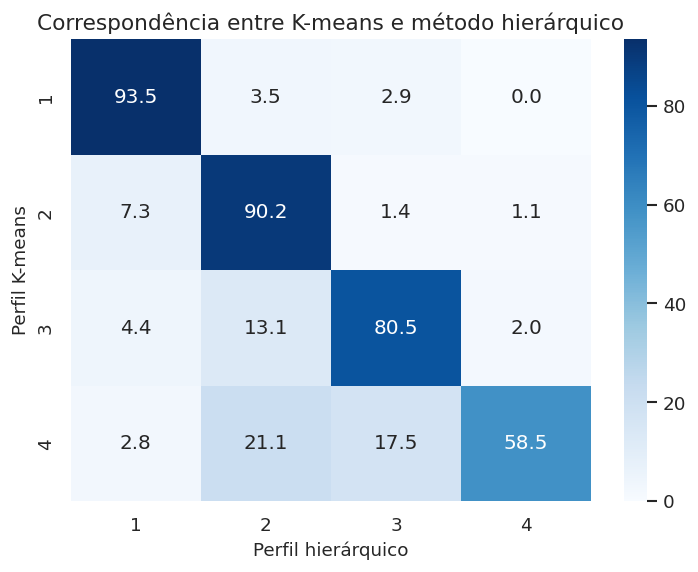

In [ ]:
modelo_hierarquico = AgglomerativeClustering(
    n_clusters=K_ESCOLHIDO,
    linkage="ward",
)
rotulos_hierarquicos_brutos = modelo_hierarquico.fit_predict(X_padronizado)

aux_h = atributos_diarios[["energia_total_kWh"]].copy()
aux_h["rotulo_bruto"] = rotulos_hierarquicos_brutos
ordem_h = (
    aux_h.groupby("rotulo_bruto")["energia_total_kWh"]
    .mean()
    .sort_values()
    .index
    .tolist()
)
mapa_h = {rotulo: posicao + 1 for posicao, rotulo in enumerate(ordem_h)}
atributos_diarios["perfil_hierarquico"] = pd.Series(
    rotulos_hierarquicos_brutos,
    index=atributos_diarios.index,
).map(mapa_h)

silhueta_h = silhouette_score(
    X_padronizado,
    rotulos_hierarquicos_brutos,
)
ari_h_k = adjusted_rand_score(
    rotulos_kmeans_brutos,
    rotulos_hierarquicos_brutos,
)

print("Silhueta do agrupamento hierárquico:", round(silhueta_h, 4))
print("ARI entre hierárquico e K-means:", round(ari_h_k, 4))

comparacao_h_k = pd.crosstab(
    atributos_diarios["perfil_kmeans"],
    atributos_diarios["perfil_hierarquico"],
    normalize="index",
) * 100

plt.figure(figsize=(7, 5))
sns.heatmap(comparacao_h_k, annot=True, fmt=".1f", cmap="Blues")
plt.title("Correspondência entre K-means e método hierárquico")
plt.xlabel("Perfil hierárquico")
plt.ylabel("Perfil K-means")
plt.show()


### Interpretação da comparação

O Adjusted Rand Index, ARI, mede concordância entre duas partições sem exigir que os números dos rótulos coincidam. Valor próximo de 1 indica forte concordância. Valor próximo de zero indica concordância semelhante ao acaso.

Concordância alta sugere que a estrutura é recuperada por dois procedimentos diferentes. Concordância baixa não identifica automaticamente qual método está correto. Ela indica que a solução depende das hipóteses do algoritmo e precisa de investigação.


## 14. DBSCAN: grupos por densidade e identificação de ruído

O DBSCAN não exige o número de grupos antecipadamente. Ele procura regiões densas no espaço.

Seus parâmetros principais são:

* eps: raio da vizinhança;
* min_samples: quantidade mínima de pontos necessária para caracterizar uma região densa.

Pontos em regiões densas formam grupos. Pontos alcançáveis expandem esses grupos. Pontos que não satisfazem os critérios recebem rótulo menos 1 e são chamados de ruído.

Um ponto de ruído não é automaticamente fraude, defeito ou erro. Ele é apenas pouco compatível com as regiões densas segundo os atributos, a escala e os parâmetros utilizados.


### 14.1 Redução para 90% da variância

O DBSCAN pode sofrer em espaços com muitas dimensões porque as distâncias tendem a se tornar menos contrastantes. Será utilizada uma representação PCA que preserva pelo menos 90% da variância.

Para apoiar a escolha de eps, calcula-se a distância de cada ponto ao seu k-ésimo vizinho. A curva dessas distâncias costuma apresentar uma região de mudança de inclinação. Como a seleção visual nem sempre é clara, também será executada uma busca exploratória em quantis da curva.


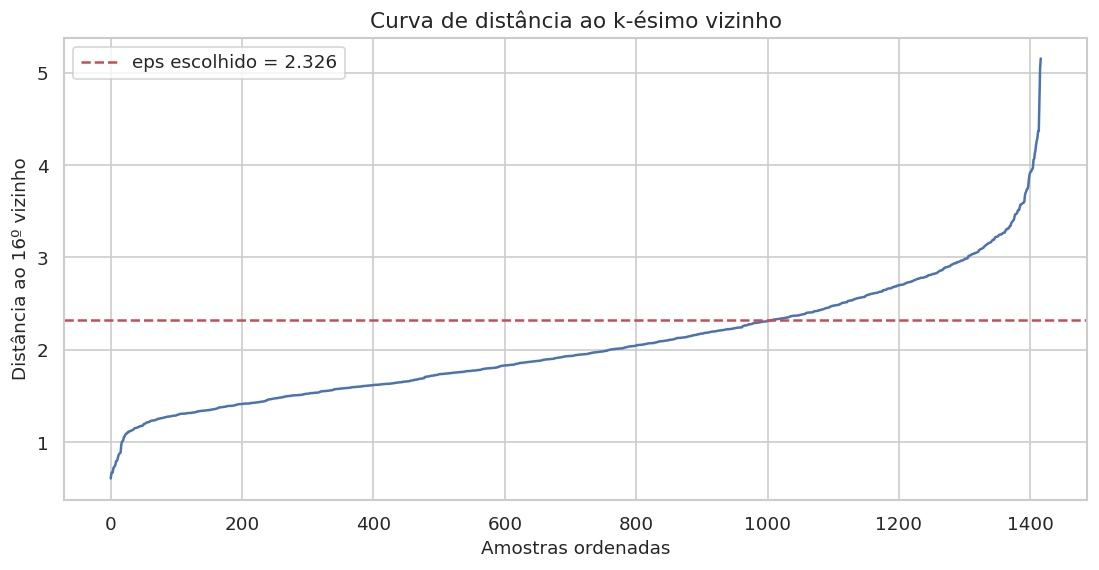

Componentes PCA utilizadas: 8
Variância preservada: 0.9002
min_samples: 16
eps sugerido pela busca: 2.3265


,eps,grupos,fracao_ruido,silhueta_sem_ruido
0,2.3038,1,0.1143,NaN
1,2.3265,2,0.0932,0.2918
2,2.3449,1,0.0868,NaN
3,2.3709,1,0.0797,NaN
4,2.4023,1,0.0685,NaN
5,2.4253,1,0.0635,NaN
6,2.4627,1,0.0572,NaN
7,2.5003,1,0.0501,NaN
8,2.5386,1,0.0423,NaN
9,2.5715,1,0.0388,NaN


In [ ]:
pca_90 = PCA(n_components=0.90, svd_solver="full")
X_pca_90 = pca_90.fit_transform(X_padronizado)

MIN_SAMPLES = max(5, 2 * X_pca_90.shape[1])

vizinhos = NearestNeighbors(n_neighbors=MIN_SAMPLES)
vizinhos.fit(X_pca_90)
distancias, _ = vizinhos.kneighbors(X_pca_90)
distancia_k = np.sort(distancias[:, -1])

quantis_testados = np.linspace(0.70, 0.98, 24)
eps_testados = np.unique(np.quantile(distancia_k, quantis_testados))

resultados_dbscan = []
for eps in eps_testados:
    rotulos = DBSCAN(
        eps=float(eps),
        min_samples=MIN_SAMPLES,
    ).fit_predict(X_pca_90)

    mascara_nucleo = rotulos != -1
    grupos = len(set(rotulos)) - (1 if -1 in rotulos else 0)
    fracao_ruido = float((rotulos == -1).mean())

    silhueta = np.nan
    if grupos >= 2 and mascara_nucleo.sum() > grupos:
        silhueta = silhouette_score(
            X_pca_90[mascara_nucleo],
            rotulos[mascara_nucleo],
        )

    resultados_dbscan.append(
        {
            "eps": float(eps),
            "grupos": grupos,
            "fracao_ruido": fracao_ruido,
            "silhueta_sem_ruido": silhueta,
        }
    )

busca_dbscan = pd.DataFrame(resultados_dbscan)

candidatos = busca_dbscan[
    busca_dbscan["grupos"].between(2, 8)
    & busca_dbscan["fracao_ruido"].between(0.01, 0.35)
    & busca_dbscan["silhueta_sem_ruido"].notna()
]

if candidatos.empty:
    candidatos = busca_dbscan[
        (busca_dbscan["grupos"] >= 2)
        & busca_dbscan["silhueta_sem_ruido"].notna()
    ]

if candidatos.empty:
    EPS_ESCOLHIDO = float(np.quantile(distancia_k, 0.90))
else:
    EPS_ESCOLHIDO = float(
        candidatos.sort_values(
            ["silhueta_sem_ruido", "fracao_ruido"],
            ascending=[False, True],
        ).iloc[0]["eps"]
    )

plt.figure(figsize=(11, 5))
plt.plot(distancia_k, color="#4c72b0")
plt.axhline(
    EPS_ESCOLHIDO,
    color="#c44e52",
    linestyle="--",
    label=f"eps escolhido = {EPS_ESCOLHIDO:.3f}",
)
plt.xlabel("Amostras ordenadas")
plt.ylabel(f"Distância ao {MIN_SAMPLES}º vizinho")
plt.title("Curva de distância ao k-ésimo vizinho")
plt.legend()
plt.show()

print("Componentes PCA utilizadas:", X_pca_90.shape[1])
print("Variância preservada:", round(pca_90.explained_variance_ratio_.sum(), 4))
print("min_samples:", MIN_SAMPLES)
print("eps sugerido pela busca:", round(EPS_ESCOLHIDO, 4))
display(busca_dbscan.round(4))


### Interpretação da busca

eps pequeno produz muitas observações de ruído e pode fragmentar a base. eps grande conecta regiões distintas e pode produzir um único grupo.

A busca automática é uma heurística didática. Ela testa apenas um conjunto finito de valores e favorece soluções com dois a oito grupos, ruído entre 1% e 35% e boa silhueta entre os pontos não classificados como ruído.

Em uma aplicação real, eps e min_samples devem ser submetidos a análise de sensibilidade. Pequenas mudanças de parâmetro não deveriam transformar completamente uma conclusão operacional crítica.


Grupos encontrados: 2
Percentual de ruído: 9.32
Silhueta sem os pontos de ruído: 0.2918


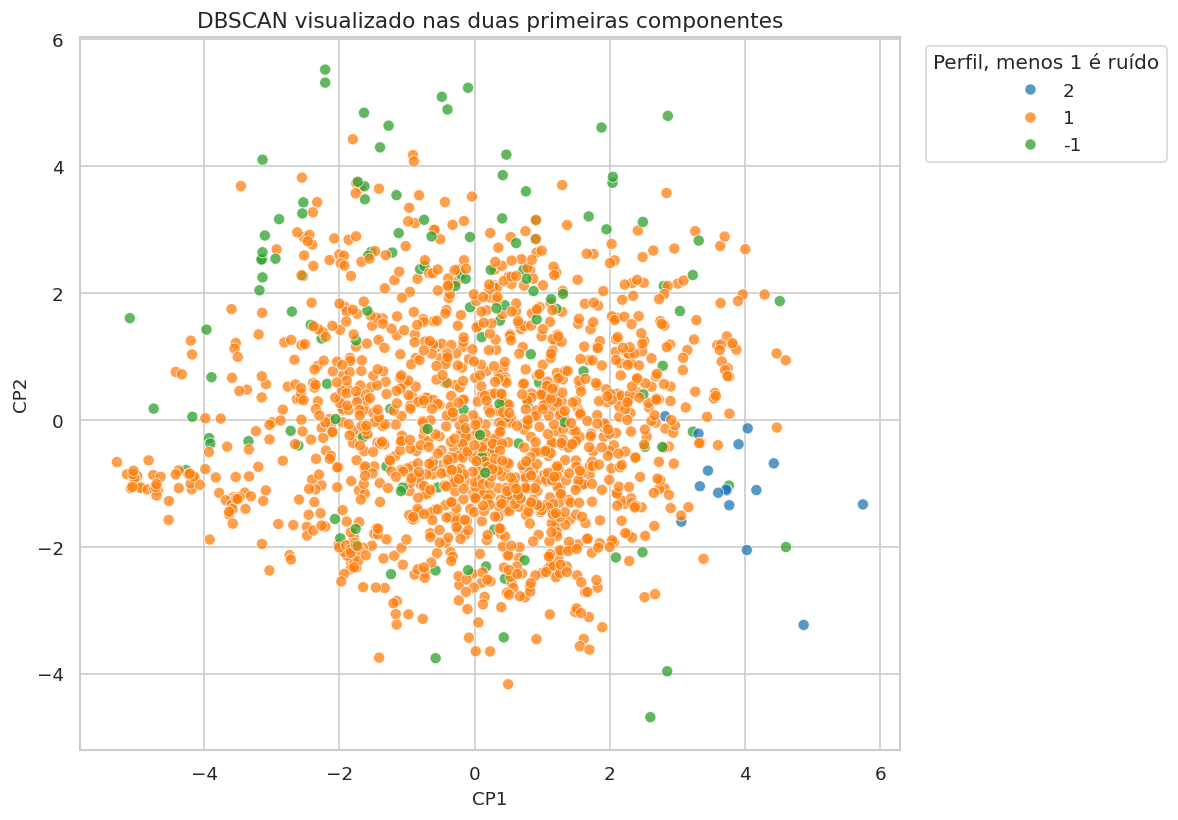

In [ ]:
modelo_dbscan = DBSCAN(
    eps=EPS_ESCOLHIDO,
    min_samples=MIN_SAMPLES,
)
rotulos_dbscan_brutos = modelo_dbscan.fit_predict(X_pca_90)

grupos_dbscan = sorted(set(rotulos_dbscan_brutos) - {-1})
numero_grupos_dbscan = len(grupos_dbscan)
percentual_ruido_dbscan = 100 * np.mean(rotulos_dbscan_brutos == -1)

aux_db = atributos_diarios[["energia_total_kWh"]].copy()
aux_db["rotulo_bruto"] = rotulos_dbscan_brutos
ordem_db = (
    aux_db[aux_db["rotulo_bruto"] != -1]
    .groupby("rotulo_bruto")["energia_total_kWh"]
    .mean()
    .sort_values()
    .index
    .tolist()
)
mapa_db = {
    rotulo: posicao + 1
    for posicao, rotulo in enumerate(ordem_db)
}
mapa_db[-1] = -1
atributos_diarios["perfil_dbscan"] = pd.Series(
    rotulos_dbscan_brutos,
    index=atributos_diarios.index,
).map(mapa_db)

print("Grupos encontrados:", numero_grupos_dbscan)
print("Percentual de ruído:", round(percentual_ruido_dbscan, 2))

if numero_grupos_dbscan >= 2:
    mascara = rotulos_dbscan_brutos != -1
    sil_db = silhouette_score(
        X_pca_90[mascara],
        rotulos_dbscan_brutos[mascara],
    )
    print("Silhueta sem os pontos de ruído:", round(sil_db, 4))
else:
    print("A silhueta exige pelo menos dois grupos e não foi calculada.")

projecao_db = projecao_2d.copy()
projecao_db["perfil"] = atributos_diarios["perfil_dbscan"].astype(str)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=projecao_db,
    x="CP1",
    y="CP2",
    hue="perfil",
    palette="tab10",
    alpha=0.75,
    s=45,
)
plt.title("DBSCAN visualizado nas duas primeiras componentes")
plt.legend(title="Perfil, menos 1 é ruído",
           bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### 14.2 Inspeção dos dias classificados como ruído

A tabela seguinte apresenta os dias de ruído e os ordena pela energia total. Ela serve para iniciar uma investigação, não para concluir que existe defeito.


In [ ]:
colunas_inspecao_ruido = [
    "energia_total_kWh",
    "demanda_pico_kW",
    "fator_carga",
    "coeficiente_variacao",
    "tensao_media_V",
    "tensao_desvio_V",
    "hora_pico",
    "dia_semana",
    "mes",
]

dias_ruido = (
    atributos_diarios.loc[
        atributos_diarios["perfil_dbscan"] == -1,
        colunas_inspecao_ruido,
    ]
    .sort_values("energia_total_kWh", ascending=False)
)

print("Quantidade de dias classificados como ruído:", len(dias_ruido))
display(dias_ruido.head(15).round(3))


Quantidade de dias classificados como ruído: 132


,energia_total_kWh,demanda_pico_kW,fator_carga,coeficiente_variacao,tensao_media_V,tensao_desvio_V,hora_pico,dia_semana,mes
data,,,,,,,,,
2006-12-31,58.237000,6.722,0.361,0.480,239.897003,3.479,8,domingo,12
2007-01-21,56.787998,8.018,0.295,0.784,238.968002,4.215,20,domingo,1
2007-02-22,56.290001,9.410,0.249,0.665,238.619995,3.328,21,quinta,2
2006-12-29,52.907001,7.238,0.305,0.596,240.871002,4.831,21,sexta,12
2007-02-20,52.499001,8.374,0.261,0.594,239.865005,2.693,7,terca,2
2008-12-27,49.535999,5.548,0.372,0.359,243.311996,2.265,22,sabado,12
2007-12-02,49.103001,8.594,0.238,0.694,240.729996,2.912,15,domingo,12
2008-01-13,48.102001,6.922,0.290,0.708,239.746994,3.390,0,domingo,1
2008-04-12,46.667000,9.482,0.205,0.841,241.063004,2.387,18,sabado,4


### Investigação correta de uma observação atípica

Um dia de ruído pode resultar de:

* consumo realmente raro;
* combinação incomum de horário, energia e pico;
* feriado, ausência dos moradores ou evento doméstico;
* alteração de equipamento;
* erro ou manutenção do medidor;
* inadequação dos atributos ou dos parâmetros.

A análise responsável exige retornar à série temporal do dia, verificar dados vizinhos e consultar informações operacionais externas.


## 15. Misturas gaussianas

O Gaussian Mixture Model, GMM, representa os dados como uma combinação de distribuições gaussianas multivariadas. Diferentemente do K-means, que fornece associação rígida, o GMM calcula a probabilidade de cada amostra pertencer a cada componente.

Um dia pode apresentar 55% de probabilidade no componente A e 45% no B. Essa informação mostra que o ponto está em uma região de transição.

O modelo será ajustado na representação PCA com 90% da variância. Serão testados diferentes números de componentes. AIC e BIC equilibram qualidade de ajuste e complexidade. Valores menores são preferíveis. O BIC penaliza a complexidade de modo mais forte.


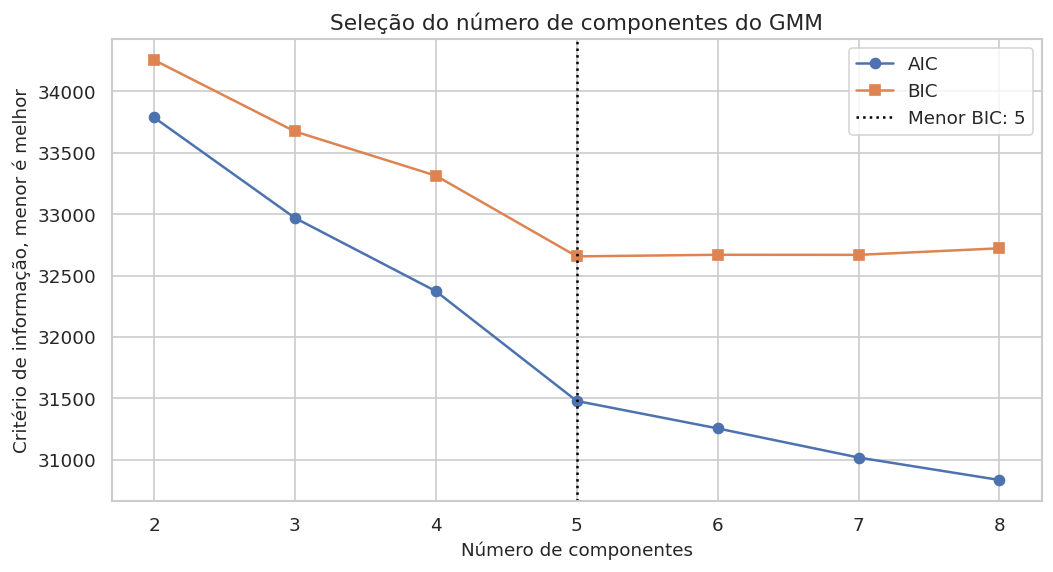

,componentes,AIC,BIC
0,2,33787.5,34255.3
1,3,32969.0,33673.4
2,4,32372.6,33313.4
3,5,31478.5,32656.0
4,6,31255.1,32669.1
5,7,31017.9,32668.4
6,8,30834.9,32721.9


Número selecionado pelo BIC: 5


In [ ]:
resultados_gmm = []
modelos_gmm = {}

for componentes in range(2, 9):
    modelo = GaussianMixture(
        n_components=componentes,
        covariance_type="full",
        n_init=5,
        reg_covar=1e-6,
        random_state=SEMENTE,
    )
    modelo.fit(X_pca_90)
    modelos_gmm[componentes] = modelo
    resultados_gmm.append(
        {
            "componentes": componentes,
            "AIC": modelo.aic(X_pca_90),
            "BIC": modelo.bic(X_pca_90),
        }
    )

avaliacao_gmm = pd.DataFrame(resultados_gmm)
COMPONENTES_GMM = int(
    avaliacao_gmm.loc[avaliacao_gmm["BIC"].idxmin(), "componentes"]
)

plt.figure(figsize=(10, 5))
plt.plot(
    avaliacao_gmm["componentes"],
    avaliacao_gmm["AIC"],
    marker="o",
    label="AIC",
)
plt.plot(
    avaliacao_gmm["componentes"],
    avaliacao_gmm["BIC"],
    marker="s",
    label="BIC",
)
plt.axvline(
    COMPONENTES_GMM,
    color="black",
    linestyle=":",
    label=f"Menor BIC: {COMPONENTES_GMM}",
)
plt.xlabel("Número de componentes")
plt.ylabel("Critério de informação, menor é melhor")
plt.title("Seleção do número de componentes do GMM")
plt.legend()
plt.show()

display(avaliacao_gmm.round(1))
print("Número selecionado pelo BIC:", COMPONENTES_GMM)


### Interpretação de AIC e BIC

AIC e BIC não possuem um valor absoluto universalmente bom. Eles servem para comparar modelos ajustados à mesma base e com a mesma representação.

Se a curva continuar diminuindo até o maior número testado, o intervalo pode ter sido insuficiente ou o modelo pode estar usando componentes adicionais para representar formas não gaussianas. A escolha ainda precisa ser examinada por estabilidade e significado.


Confiança mediana: 0.9511
Percentual de dias com confiança inferior a 70%: 19.2


,perfil_gmm,confianca_gmm,energia_total_kWh,demanda_pico_kW,fator_carga,hora_pico
data,,,,,,
2007-01-18,2,0.313,30.358000,6.808,0.186,18
2007-02-16,4,0.333,28.375000,6.316,0.187,6
2008-01-06,5,0.350,30.420000,6.376,0.199,19
2008-07-28,4,0.366,13.763000,5.044,0.114,7
2008-03-22,3,0.366,34.224998,6.086,0.234,20
2010-03-01,3,0.373,21.645000,4.682,0.193,11
2010-09-19,4,0.382,15.327000,3.762,0.170,20
2006-12-21,5,0.387,28.618999,5.854,0.204,9
2007-10-24,4,0.391,31.094000,5.826,0.222,19


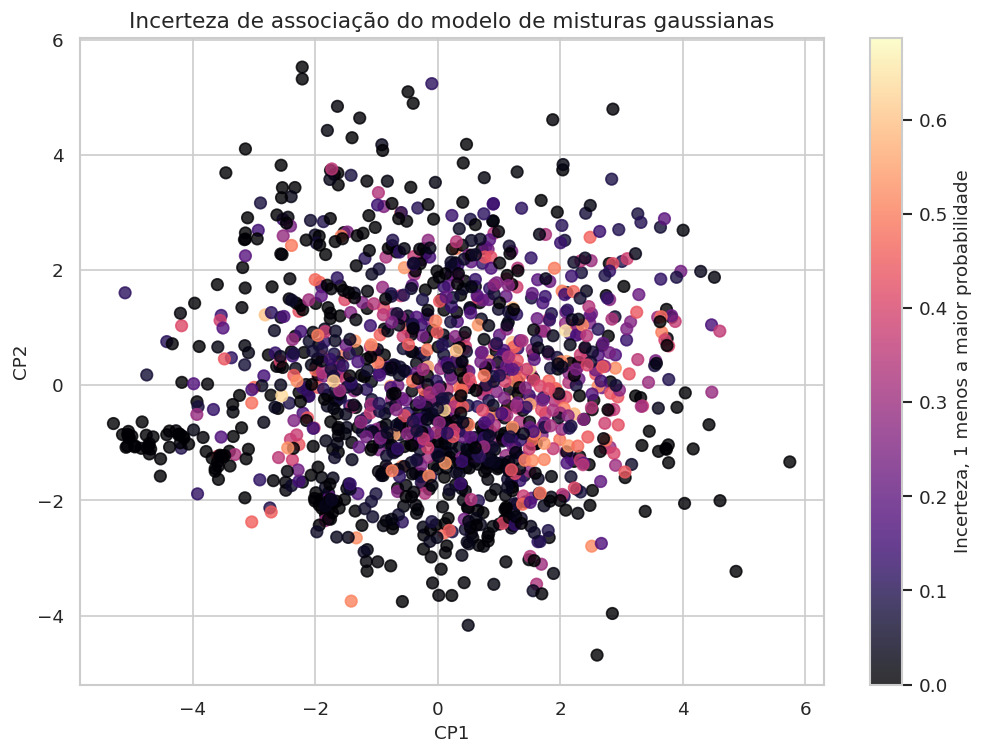

In [ ]:
modelo_gmm = modelos_gmm[COMPONENTES_GMM]
rotulos_gmm_brutos = modelo_gmm.predict(X_pca_90)
probabilidades_gmm = modelo_gmm.predict_proba(X_pca_90)
confianca_maxima = probabilidades_gmm.max(axis=1)
incerteza_gmm = 1 - confianca_maxima

aux_gmm = atributos_diarios[["energia_total_kWh"]].copy()
aux_gmm["rotulo_bruto"] = rotulos_gmm_brutos
ordem_gmm = (
    aux_gmm.groupby("rotulo_bruto")["energia_total_kWh"]
    .mean()
    .sort_values()
    .index
    .tolist()
)
mapa_gmm = {
    rotulo: posicao + 1
    for posicao, rotulo in enumerate(ordem_gmm)
}

atributos_diarios["perfil_gmm"] = pd.Series(
    rotulos_gmm_brutos,
    index=atributos_diarios.index,
).map(mapa_gmm)
atributos_diarios["confianca_gmm"] = confianca_maxima
atributos_diarios["incerteza_gmm"] = incerteza_gmm

print("Confiança mediana:", round(float(np.median(confianca_maxima)), 4))
print("Percentual de dias com confiança inferior a 70%:",
      round(100 * float(np.mean(confianca_maxima < 0.70)), 2))

dias_incertos = (
    atributos_diarios[
        [
            "perfil_gmm",
            "confianca_gmm",
            "energia_total_kWh",
            "demanda_pico_kW",
            "fator_carga",
            "hora_pico",
        ]
    ]
    .sort_values("confianca_gmm")
    .head(15)
)
display(dias_incertos.round(3))

projecao_gmm = projecao_2d.copy()
projecao_gmm["perfil"] = atributos_diarios["perfil_gmm"]
projecao_gmm["incerteza"] = atributos_diarios["incerteza_gmm"]

plt.figure(figsize=(10, 7))
grafico = plt.scatter(
    projecao_gmm["CP1"],
    projecao_gmm["CP2"],
    c=projecao_gmm["incerteza"],
    cmap="magma",
    s=48,
    alpha=0.8,
)
plt.colorbar(grafico, label="Incerteza, 1 menos a maior probabilidade")
plt.xlabel("CP1")
plt.ylabel("CP2")
plt.title("Incerteza de associação do modelo de misturas gaussianas")
plt.show()


### Como interpretar a incerteza

Confiança próxima de um significa que uma componente recebeu probabilidade muito maior que as demais. Confiança próxima de 0,5, em um problema com duas componentes, indica fronteira ambígua.

A probabilidade é condicionada ao modelo. Ela não significa probabilidade física de o dia ser normal nem garantia estatística universal. Se as distribuições gaussianas forem uma aproximação inadequada, as probabilidades também serão inadequadas.


## 16. Comparação dos métodos

Métodos diferentes respondem a perguntas ligeiramente diferentes:

| Método | Estrutura procurada | Associação de novo ponto | Tratamento de ruído |
|---|---|---|---|
| K-means | grupos compactos em torno de médias | direta pelo centroide mais próximo | não separa ruído |
| Hierárquico de Ward | hierarquia com baixo aumento de variância | não é direto no modelo utilizado | não separa ruído |
| DBSCAN | regiões densas conectadas | não é direto na implementação padrão | rótulo menos 1 |
| GMM | mistura de distribuições gaussianas | direta e probabilística | não separa ruído explicitamente |

A comparação seguinte utiliza o mesmo espaço padronizado para as métricas internas. No DBSCAN, os pontos de ruído são retirados apenas para o cálculo dessas métricas, e a fração removida é informada.


In [ ]:
def calcular_metricas_particao(nome, rotulos, X, rotulos_referencia=None):
    rotulos = np.asarray(rotulos)
    mascara = rotulos != -1
    rotulos_validos = rotulos[mascara]
    X_valido = X[mascara]
    quantidade_grupos = len(np.unique(rotulos_validos))

    resultado = {
        "metodo": nome,
        "grupos": quantidade_grupos,
        "ruido_percentual": 100 * np.mean(~mascara),
        "silhueta": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
        "ARI_com_Kmeans": np.nan,
    }

    if quantidade_grupos >= 2 and len(rotulos_validos) > quantidade_grupos:
        resultado["silhueta"] = silhouette_score(X_valido, rotulos_validos)
        resultado["davies_bouldin"] = davies_bouldin_score(
            X_valido,
            rotulos_validos,
        )
        resultado["calinski_harabasz"] = calinski_harabasz_score(
            X_valido,
            rotulos_validos,
        )

    if rotulos_referencia is not None:
        resultado["ARI_com_Kmeans"] = adjusted_rand_score(
            np.asarray(rotulos_referencia)[mascara],
            rotulos_validos,
        )

    return resultado


linhas_comparacao = [
    calcular_metricas_particao(
        "K-means",
        rotulos_kmeans_brutos,
        X_padronizado,
        rotulos_kmeans_brutos,
    ),
    calcular_metricas_particao(
        "Hierárquico",
        rotulos_hierarquicos_brutos,
        X_padronizado,
        rotulos_kmeans_brutos,
    ),
    calcular_metricas_particao(
        "DBSCAN",
        rotulos_dbscan_brutos,
        X_padronizado,
        rotulos_kmeans_brutos,
    ),
    calcular_metricas_particao(
        "GMM",
        rotulos_gmm_brutos,
        X_padronizado,
        rotulos_kmeans_brutos,
    ),
]

comparacao_modelos = pd.DataFrame(linhas_comparacao).set_index("metodo")
display(comparacao_modelos.round(4))


,grupos,ruido_percentual,silhueta,davies_bouldin,calinski_harabasz,ARI_com_Kmeans
metodo,,,,,,
K-means,4,0.0000,0.1545,1.7913,238.924896,1.0000
Hierárquico,4,0.0000,0.1170,1.9980,192.515198,0.5028
DBSCAN,2,9.3155,0.2776,0.9449,40.226501,0.0019
GMM,5,0.0000,0.0714,3.3425,100.609398,0.2683


### Leitura responsável da comparação

A maior silhueta não define automaticamente o melhor método. O DBSCAN pode alcançar silhueta elevada após excluir muitos pontos como ruído. Nesse caso, a fração de ruído precisa ser considerada.

O ARI com K-means mede semelhança entre partições, não qualidade absoluta. Dois métodos podem concordar e ambos representar uma simplificação pouco útil.

A seleção final deve considerar:

1. qualidade interna;
2. estabilidade;
3. número e tamanho dos grupos;
4. clareza das curvas de carga;
5. utilidade para a decisão de engenharia;
6. capacidade de tratar novos dados.


## 17. Estabilidade do K-means

Como o K-means depende da inicialização, o algoritmo será repetido com sementes diferentes. Cada solução será comparada à solução de referência por ARI.

Se o ARI permanecer próximo de um, diferentes inicializações recuperam praticamente a mesma partição. Valores baixos indicam uma solução sensível, mesmo que uma execução isolada apresente boa silhueta.


In [ ]:
estabilidade = []

for semente in range(10):
    modelo_teste = KMeans(
        n_clusters=K_ESCOLHIDO,
        init="k-means++",
        n_init=10,
        max_iter=500,
        random_state=semente,
    )
    rotulos_teste = modelo_teste.fit_predict(X_padronizado)
    estabilidade.append(
        {
            "semente": semente,
            "ARI_com_referencia": adjusted_rand_score(
                rotulos_kmeans_brutos,
                rotulos_teste,
            ),
            "inercia": modelo_teste.inertia_,
        }
    )

tabela_estabilidade = pd.DataFrame(estabilidade)
display(tabela_estabilidade.round(5))

print("ARI mínimo:", round(tabela_estabilidade["ARI_com_referencia"].min(), 4))
print("ARI médio:", round(tabela_estabilidade["ARI_com_referencia"].mean(), 4))


,semente,ARI_com_referencia,inercia
0,0,0.99381,13161.64746
1,1,0.99381,13161.64746
2,2,0.99161,13161.62793
3,3,0.99161,13161.62793
4,4,0.99381,13161.64746
5,5,0.99381,13161.64746
6,6,0.99161,13161.62793
7,7,0.99161,13161.62793
8,8,0.99381,13161.64746
9,9,0.99381,13161.64746


ARI mínimo: 0.9916
ARI médio: 0.9929


### Limite deste teste de estabilidade

O teste altera somente a semente. Ele verifica sensibilidade à inicialização, mas não verifica sensibilidade a amostragem, período histórico, atributos, escala ou hiperparâmetros.

Uma validação mais rigorosa incluiria reamostragem de dias, janelas temporais distintas e análise de estabilidade dos perfis centrais.


## 18. Associação de um novo dia

Depois de ajustado, o K-means pode associar um novo dia ao centroide mais próximo. O novo registro deve possuir exatamente os mesmos 14 atributos, na mesma ordem, e ser transformado pelo escalonador já ajustado.

A célula utiliza um dia existente apenas para demonstrar o caminho completo. Em operação, a linha seria produzida pelas medições de um novo dia.


In [ ]:
data_exemplo = X_original.index[0]
novo_dia = X_original.loc[[data_exemplo]]

novo_dia_padronizado = escalonador.transform(novo_dia)
rotulo_bruto_previsto = int(modelo_kmeans.predict(novo_dia_padronizado)[0])
perfil_previsto = mapa_ordem_kmeans[rotulo_bruto_previsto]

novo_dia_pca = pca_90.transform(novo_dia_padronizado)
probabilidades_novo_dia_brutas = modelo_gmm.predict_proba(novo_dia_pca)[0]
probabilidades_novo_dia = {
    f"Perfil {mapa_gmm[rotulo_bruto]}": round(
        float(probabilidades_novo_dia_brutas[rotulo_bruto]),
        3,
    )
    for rotulo_bruto in ordem_gmm
}

print("Data usada no exemplo:", data_exemplo.date())
print("Perfil K-means atribuído:", perfil_previsto)
print("Perfil armazenado na tabela:",
      int(atributos_diarios.loc[data_exemplo, "perfil_kmeans"]))
print("Probabilidades GMM organizadas pelos perfis exibidos:",
      probabilidades_novo_dia)


Data usada no exemplo: 2006-12-17
Perfil K-means atribuído: 4
Perfil armazenado na tabela: 4
Probabilidades GMM organizadas pelos perfis exibidos: {'Perfil 1': 0.0, 'Perfil 2': 0.0, 'Perfil 3': 0.0, 'Perfil 4': 0.0, 'Perfil 5': 1.0}


### Cuidados em produção

A igualdade entre perfil previsto e perfil armazenado confirma a consistência do caminho para o exemplo.

Antes de utilizar o modelo em produção, seria necessário:

* repetir exatamente o tratamento de ausências;
* calcular os atributos com as mesmas definições;
* verificar mudança de distribuição ao longo do tempo;
* monitorar distâncias aos centroides;
* revisar os grupos quando hábitos, equipamentos ou tarifas mudarem;
* armazenar versão do código, escalonador, PCA, modelo e lista de atributos.


## 19. O que os grupos permitem concluir

Os grupos permitem afirmar que, segundo os atributos escolhidos e a métrica utilizada, determinados dias apresentam comportamento semelhante. Eles permitem resumir curvas, comparar níveis de energia, investigar picos, identificar concentrações sazonais e selecionar dias representativos.

Os grupos não permitem afirmar, sem evidência adicional:

* qual equipamento causou um evento não submedido;
* que um dia de ruído contém defeito;
* que um perfil causou variação de tensão;
* que a mesma estrutura ocorrerá em outra cidade;
* que o número escolhido é o número verdadeiro de comportamentos;
* que os dados representam todos os consumidores de uma rede.


## 20. Limitações do estudo

1. **Representatividade:** existe apenas uma residência, localizada na França.
2. **Período histórico:** os dados são de 2006 a 2010. Equipamentos e hábitos atuais podem diferir.
3. **Contexto incompleto:** não há temperatura, tarifa, ocupação, feriados detalhados ou eventos operacionais.
4. **Agregação:** atributos diários simplificam a série e podem esconder eventos curtos.
5. **Imputação:** valores interpolados são estimativas.
6. **Métrica:** a distância euclidiana não captura deslocamentos temporais de forma flexível.
7. **Forma dos grupos:** K-means, Ward, DBSCAN e GMM assumem estruturas diferentes.
8. **Privacidade:** perfis de carga podem revelar rotina e ocupação. Aplicações reais exigem governança e proteção.

Em uma rede com muitos consumidores, também seria necessário tratar escalabilidade, heterogeneidade contratual, fases, tensão de atendimento, clima e anonimização.


## 21. Atividades orientadas

### Atividade 1: unidade de análise

Altere mentalmente a definição da amostra de dia para consumidor. Identifique quais colunas seriam necessárias e quais conclusões mudariam.

### Atividade 2: escolha de K

Selecione um K diferente do automático, execute novamente as células do K-means e compare silhueta, tamanhos e curvas. Registre se o aumento de detalhe produziu informação elétrica útil.

### Atividade 3: atributos

Retire tensao_media_V e tensao_desvio_V. Refaça o fluxo e calcule o ARI entre a nova solução e a original. Explique por que a solução mudou ou permaneceu estável.

### Atividade 4: peso de negócio

Multiplique, depois da padronização, a coluna associada à demanda de pico por dois. Observe a alteração. Explique por que essa operação equivale a aumentar o peso dessa dimensão.

### Atividade 5: DBSCAN

Modifique eps em mais e menos 10%. Compare quantidade de grupos, ruído e silhueta. Avalie a sensibilidade.

### Atividade 6: dias atípicos

Escolha um dia classificado como ruído, represente sua curva e compare-a com os dias anterior e posterior. Liste hipóteses, separando observação de interpretação.

### Atividade 7: validação externa

Compare os perfis com estação e fim de semana. Formule uma hipótese testável que exigiria uma variável externa, como temperatura.

### Atividade 8: decisão de engenharia

Selecione um perfil que pareça adequado a resposta da demanda. Indique qual carga poderia ser deslocada, para qual horário e quais informações adicionais seriam necessárias antes da intervenção.


## 22. Síntese conceitual

O aprendizado não supervisionado não começa no algoritmo. Ele começa na definição da amostra, na qualidade dos dados e na escolha de uma representação coerente.

Neste estudo:

* medições por minuto foram convertidas em descrições diárias;
* potência foi corretamente integrada para obter energia;
* atributos redundantes ou contextuais foram separados;
* escalas foram equalizadas antes do uso de distância;
* PCA mostrou direções de variação e apoiou a visualização;
* K-means produziu centroides e perfis de carga;
* o método hierárquico revelou uma organização em níveis;
* o DBSCAN procurou densidade e marcou observações pouco usuais;
* o GMM forneceu probabilidades e incerteza de associação;
* métricas, estabilidade e significado elétrico foram analisados em conjunto.

O principal resultado não é um número de grupos. É um procedimento auditável para transformar medições em hipóteses operacionais.


## 23. Glossário final

| Conceito | Definição resumida |
|---|---|
| Aprendizado não supervisionado | aprendizagem de estrutura sem variável alvo conhecida |
| Agrupamento | separação de amostras em conjuntos semelhantes |
| Atributo | medida numérica usada para descrever uma amostra |
| Padronização | transformação para média zero e desvio padrão um |
| Centroide | média vetorial que representa um grupo K-means |
| Inércia | soma das distâncias quadráticas até os centroides |
| Silhueta | medida de coesão interna e separação externa |
| Dendrograma | representação da sequência de uniões hierárquicas |
| Densidade | concentração de pontos em uma região do espaço |
| Ruído no DBSCAN | ponto não associado a uma região suficientemente densa |
| PCA | transformação linear que ordena direções pela variância |
| Componente principal | combinação linear dos atributos originais |
| GMM | mistura probabilística de gaussianas multivariadas |
| AIC e BIC | critérios que equilibram ajuste e complexidade |
| ARI | medida de concordância entre duas partições |
| Fator de carga | razão entre potência média e potência máxima |
| Perfil de carga | evolução temporal da potência ou energia |


## 24. Referências e documentação

HEBRAIL, Georges; BERARD, Alice. **Individual Household Electric Power Consumption**. UCI Machine Learning Repository, 2006. DOI: https://doi.org/10.24432/C58K54.

UCI MACHINE LEARNING REPOSITORY. **Individual Household Electric Power Consumption**. Disponível em: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption.

SCIKIT-LEARN. **Clustering**. Disponível em: https://scikit-learn.org/stable/modules/clustering.html.

SCIKIT-LEARN. **PCA**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html.

SCIKIT-LEARN. **StandardScaler**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html.

SCIKIT-LEARN. **GaussianMixture**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html.

SCIKIT-LEARN. **Clustering performance evaluation**. Disponível em: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation.
